<div style="text-align:center">

**МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РФ**  
Новосибирский государственный технический университет  
Кафедра автоматизированных систем управления

**ОТЧЁТ**  
**по лабораторной работе №2 «Классификация. Нейронные сети»**  
по дисциплине «Методы анализа данных»

</div>

Выполнили: студенты гр. АП-326, АВТФ: Симоняк С. В., Седельников А. А., Шипунов Д. Н.  
Проверил: ассистент каф. АСУ Киреенко М. А.

Новосибирск 2026

---
*Как читать этот ноутбук.* Отчёт совмещён с кодом: текст разделов идёт вместе с ячейками, которые выполняют соответствующие расчёты. Графики строятся ячейками кода; номер «Рисунок N» указан в левом верхнем углу каждого графика и соответствует ссылкам в тексте. Числа в тексте получены при запуске с `random_state = 44`; при повторном обучении нейронной сети значения могут слегка отличаться (TensorFlow не гарантирует побитовой воспроизводимости).

# ВВЕДЕНИЕ

Цель работы – изучение методов классификации данных, реализованных в библиотеке Scikit-Learn, и знакомство с нейронными сетями на основе библиотек TensorFlow и TensorBoard.

Для достижения цели в соответствии с заданием необходимо выполнить следующие задачи:

1. выбрать и подготовить набор данных для классификации;
2. разделить данные на обучающее и тестовое подмножества;
3. построить классификаторы пятью методами: наивный байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, линейный дискриминантный анализ, метод опорных векторов и метод k ближайших соседей;
4. сравнить качество классификаторов по метрикам accuracy, precision, recall, F1 и площади под ROC-кривой (AUC-ROC);
5. настроить гиперпараметры каждого метода и исследовать их влияние на качество классификации;
6. реализовать нейронную сеть на TensorFlow, исследовать влияние гиперпараметров и визуализировать обучение в TensorBoard;
7. выполнить сравнительный анализ и выбрать лучший подход для выбранного набора данных.

Работа продолжает предыдущую лабораторную работу: используются тот же набор данных, тот же набор признаков и то же разбиение на обучающее и тестовое подмножества, что позволяет сопоставить результаты с ранее полученными для дерева решений и метода опорных векторов.

In [23]:
import os, time, gc, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from scipy.stats import binomtest
import tensorflow as tf
import keras

warnings.filterwarnings("ignore")      # фильтр ставится после импортов, чтобы библиотеки его не сбросили
sns.set_theme(style="whitegrid")

FAST = False                           # True - только отладка на малой выборке и коротких обучениях
RS = 44                                # random_state как в предыдущей работе
DATA_PATH, SHEET, TARGET = "Dry_Bean_Dataset.xlsx", "Dry_Beans_Dataset", "Class"
OUT = "out_fast" if FAST else "out"; CACHE = "cache_fast" if FAST else "cache"; LOGS = "logs_fast" if FAST else "logs"
for d in (OUT, CACHE): os.makedirs(d, exist_ok=True)
np.random.seed(RS); keras.utils.set_random_seed(RS)

def cached(name, fn):
    """Долгие расчёты сохраняются на диск, повторный запуск ячейки их не пересчитывает."""
    path = f"{CACHE}/{name}.joblib"
    if os.path.exists(path):
        return joblib.load(path)
    res = fn(); joblib.dump(res, path); return res

# 1 Выбор и подготовка датасета

## 1.1 Выбор и описание датасета

Для работы выбран набор данных Dry Bean Dataset из репозитория UCI Machine Learning Repository [1]. Авторы набора [2] по фотографиям 13611 зёрен семи сортов сухой фасоли выделили контур каждого зерна и рассчитали по нему 12 размерных характеристик и 4 коэффициента формы. Требуется определить сорт зерна по этим признакам, то есть решить задачу многоклассовой классификации.

Набор подходит для работы: он содержит много объектов, только количественные признаки и семь классов разного размера, поэтому метрики с макроусреднением по классам отличаются от общей точности. Набор тот же, что в предыдущей работе, поэтому описание признаков приведено кратко.

Набор содержит 13611 объектов и 17 столбцов: 16 количественных признаков и целевую переменную Class с семью классами. Пропущенных значений нет. Описание признаков приведено в таблице 1, где A – площадь, P – периметр, L и l – длины большой и малой осей, C – площадь выпуклой оболочки зерна.

**Таблица 1 – Признаки набора данных Dry Bean Dataset**

| № | Признак | Описание | Расчёт |
|---|---|---|---|
| 1 | Area | Площадь зерна (число пикселей внутри контура) | A |
| 2 | Perimeter | Длина контура зерна | P |
| 3 | MajorAxisLength | Длина большой оси – наибольшего отрезка внутри контура | L |
| 4 | MinorAxisLength | Длина малой оси – наибольшего отрезка, перпендикулярного большой оси | l |
| 5 | AspectRation | Отношение длин осей (удлинённость) | L / l |
| 6 | Eccentricity | Эксцентриситет эллипса с теми же моментами, что и контур | √(1 − (l / L)<sup>2</sup>) |
| 7 | ConvexArea | Площадь наименьшего выпуклого многоугольника, содержащего зерно | C |
| 8 | EquivDiameter | Диаметр круга той же площади, что и зерно | √(4A / π) |
| 9 | Extent | Отношение площади зерна к площади описанного прямоугольника | A / A<sub>прям</sub> |
| 10 | Solidity | Выпуклость (доля площади выпуклой оболочки, занятая зерном) | A / C |
| 11 | roundness | Округлость | 4πA / P<sup>2</sup> |
| 12 | Compactness | Компактность | EquivDiameter / L |
| 13 | ShapeFactor1 | Коэффициент формы 1 | L / A |
| 14 | ShapeFactor2 | Коэффициент формы 2 | A / L<sup>3</sup> |
| 15 | ShapeFactor3 | Коэффициент формы 3 | 4A / (πL<sup>2</sup>) |
| 16 | ShapeFactor4 | Коэффициент формы 4 | 4A / (πLl) |
| 17 | Class | Сорт фасоли (целевая переменная) | 7 категорий |

Признаки делятся на две группы. Размерные признаки (Area, Perimeter, MajorAxisLength, MinorAxisLength, ConvexArea, EquivDiameter) описывают величину зерна в пикселях. Коэффициенты формы рассчитываются как отношения размерных характеристик и от величины зерна не зависят, кроме ShapeFactor1 и ShapeFactor2, которые зависят и от формы, и от размера.

## 1.2 Целевая переменная и классы

Целевая переменная Class принимает семь значений – сортов фасоли. Число объектов в классах приведено в таблице 2.

**Таблица 2 – Распределение объектов по классам**

| Класс | Число объектов | Доля, % |
|---|---|---|
| DERMASON | 3546 | 26,05 |
| SIRA | 2636 | 19,37 |
| SEKER | 2027 | 14,89 |
| HOROZ | 1928 | 14,17 |
| CALI | 1630 | 11,98 |
| BARBUNYA | 1322 | 9,71 |
| BOMBAY | 522 | 3,84 |
| Всего | 13611 | 100,00 |

Классы несбалансированы: самый большой класс DERMASON составляет 26,1 % набора, самый малый BOMBAY – 3,8 %, отношение размеров классов равно 6,8. Поэтому общая точность (accuracy) в основном отражает качество на крупных классах, а для оценки используются также метрики с макроусреднением, которые придают всем классам одинаковый вес. Дисбаланс также учитывается параметром class_weight в методах, где он предусмотрен.

## 1.3 Предобработка данных

Пропущенных значений в наборе нет. В наборе есть 68 полностью совпадающих строк (0,5 %), они оставлены без изменений, как и в предыдущей работе, так как их доля мала и не влияет на выводы.

Из 16 признаков в предыдущей работе отобраны 9: удалены семь признаков, дублирующих другие (модуль коэффициента корреляции Пирсона больше 0,95): Area, MajorAxisLength, ConvexArea, EquivDiameter, AspectRation, Eccentricity и ShapeFactor3. Из каждой пары сильно коррелирующих признаков оставлялся признак с большей взаимной информацией с классом. Отобранные признаки: Perimeter, MinorAxisLength, Extent, Solidity, roundness, Compactness, ShapeFactor1, ShapeFactor2 и ShapeFactor4. Корреляционная матрица отобранных признаков по обучающему подмножеству показана на рисунке 1.

Наибольший по модулю коэффициент корреляции оставшихся признаков равен −0,95 (MinorAxisLength и ShapeFactor1), остальные пары связаны слабее. Отбор выполнялся по всей выборке; при отборе только по обучающему подмножеству меняется лишь выбор между Compactness и ShapeFactor3, которые связаны монотонной зависимостью (ShapeFactor3 равен квадрату Compactness), поэтому на результаты это практически не влияет.

Масштабы отобранных признаков различаются очень сильно (таблица 3): стандартное отклонение изменяется от 0,0006 до 214,3, то есть примерно в 363 тыс. раз. Для методов, зависящих от расстояний или от дисперсий признаков, это недопустимо, поэтому признаки приводятся к единому масштабу.

**Таблица 3 – Масштабы отобранных признаков (обучающее подмножество)**

| Признак | Среднее | Ст. откл. | Минимум | Максимум |
|---|---|---|---|---|
| Perimeter | 855,7557 | 214,3300 | 530,6830 | 1985,3700 |
| MinorAxisLength | 202,4123 | 45,1132 | 122,5126 | 460,1985 |
| Extent | 0,7498 | 0,0491 | 0,5553 | 0,8584 |
| Solidity | 0,9872 | 0,0046 | 0,9193 | 0,9944 |
| roundness | 0,8735 | 0,0591 | 0,4896 | 0,9907 |
| Compactness | 0,7998 | 0,0617 | 0,6406 | 0,9873 |
| ShapeFactor1 | 0,0066 | 0,0011 | 0,0028 | 0,0104 |
| ShapeFactor2 | 0,0017 | 0,0006 | 0,0006 | 0,0037 |
| ShapeFactor4 | 0,9951 | 0,0043 | 0,9477 | 0,9997 |

Стандартизация выполняется по формуле

$$
z=\frac{x-\bar{x}_{\mathrm{train}}}{s_{\mathrm{train}}},\qquad\qquad \text{(1)}
$$

где <i>x</i> – исходное значение признака; среднее и стандартное отклонение рассчитываются только по обучающему подмножеству, иначе сведения о тестовых объектах попали бы в модель и завысили бы оценку качества. Для этого все преобразования включены в конвейеры (Pipeline) вместе с классификатором, и при кросс-валидации параметры преобразований заново рассчитываются по обучающей части каждого фолда.

Требования к входным данным у методов различаются, поэтому предобработка подбиралась под метод (таблица 4). Многочленный (MultinomialNB) и дополняющий (ComplementNB) наивные байесовские классификаторы рассчитаны на неотрицательные признаки-частоты, а BernoulliNB – на бинарные признаки. Для них применены два способа: приведение признаков к диапазону [0; 1] (с ограничением значений тестовых объектов границами обучающего диапазона) либо дискретизация каждого признака на интервалы по квантилям с кодированием «один из n» (one-hot), при которой признаки становятся индикаторами попадания в интервал.

**Таблица 4 – Предобработка признаков для разных методов**

| Метод | Предобработка |
|---|---|
| GaussianNB | стандартизация |
| MultinomialNB, ComplementNB | приведение к диапазону [0; 1] или дискретизация на интервалы |
| BernoulliNB | стандартизация и бинаризация по порогу или дискретизация на интервалы |
| Дерево решений | не требуется (линейное преобразование не меняет разбиений) |
| LDA, SVM, kNN | стандартизация |
| Нейронная сеть | стандартизация |

Размер: (13611, 17) | пропусков: 0 | полных дубликатов строк: 68
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
train: (9527, 9) | test: (4084, 9)


,"train, n","test, n","train, %","test, %"
BARBUNYA,925,397,9.71,9.72
BOMBAY,365,157,3.83,3.84
CALI,1141,489,11.98,11.97
DERMASON,2482,1064,26.05,26.05
HOROZ,1350,578,14.17,14.15
SEKER,1419,608,14.89,14.89
SIRA,1845,791,19.37,19.37


,mean,std,min,max
Perimeter,855.75568,214.32996,530.68300,1985.37000
MinorAxisLength,202.41230,45.11316,122.51265,460.19850
Extent,0.74982,0.04912,0.55531,0.85842
Solidity,0.98717,0.00461,0.91925,0.99438
roundness,0.87347,0.05914,0.48962,0.99069
Compactness,0.79978,0.06173,0.64058,0.98730
ShapeFactor1,0.00656,0.00113,0.00278,0.01045
ShapeFactor2,0.00171,0.00059,0.00056,0.00366
ShapeFactor4,0.99507,0.00435,0.94769,0.99971


Разброс std: в 360454 раз


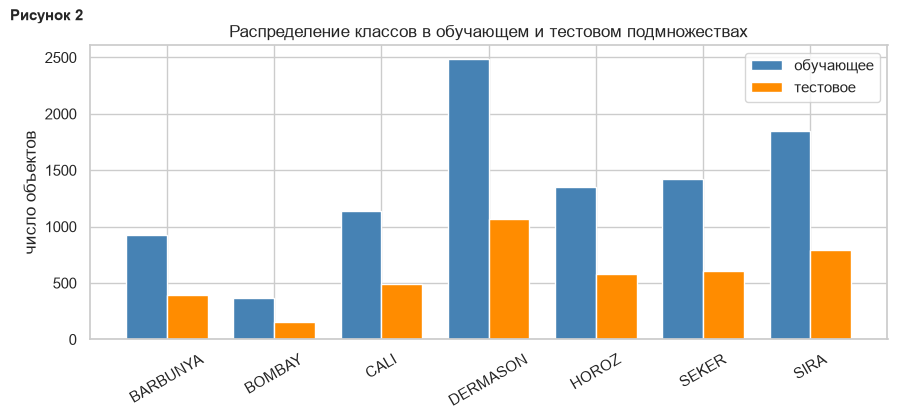

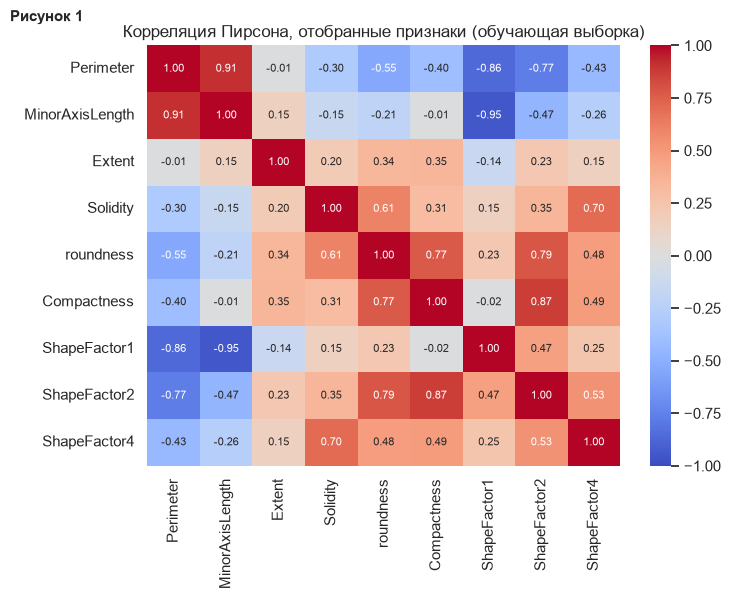

In [24]:
df = pd.read_excel(DATA_PATH, sheet_name=SHEET)
if FAST:
    df = train_test_split(df, train_size=2500, stratify=df[TARGET], random_state=RS)[0].reset_index(drop=True)
FEATURES = [c for c in df.columns if c != TARGET]
print("Размер:", df.shape, "| пропусков:", int(df.isna().sum().sum()), "| полных дубликатов строк:", int(df.duplicated().sum()))
print(df[TARGET].value_counts().to_string())

# 9 признаков, отобранных в предыдущей работе (удалены дубли с |r| > 0.95 по взаимной информации)
SELECTED = ["Perimeter", "MinorAxisLength", "Extent", "Solidity", "roundness",
            "Compactness", "ShapeFactor1", "ShapeFactor2", "ShapeFactor4"]

le = LabelEncoder()
y = pd.Series(le.fit_transform(df[TARGET]), index=df.index, name=TARGET)
CLASSES = list(le.classes_); K = len(CLASSES)
X_train, X_test, y_train, y_test = train_test_split(df[SELECTED], y, test_size=0.30, random_state=RS, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape)

split_tbl = pd.DataFrame({"train, n": y_train.value_counts().sort_index(), "test, n": y_test.value_counts().sort_index()})
split_tbl.index = CLASSES
split_tbl["train, %"] = split_tbl["train, n"] / len(y_train) * 100
split_tbl["test, %"] = split_tbl["test, n"] / len(y_test) * 100
split_tbl.round(2).to_csv(f"{OUT}/split_table.csv"); display(split_tbl.round(2))

scale_tbl = X_train.describe().T[["mean", "std", "min", "max"]]
scale_tbl.round(5).to_csv(f"{OUT}/scale_table.csv"); display(scale_tbl.round(5))
print("Разброс std: в %.0f раз" % (scale_tbl["std"].max() / scale_tbl["std"].min()))

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(K); w = 0.38
ax.bar(x - w / 2, split_tbl["train, n"], w, label="обучающее", color="steelblue")
ax.bar(x + w / 2, split_tbl["test, n"], w, label="тестовое", color="darkorange")
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=30); ax.set_ylabel("число объектов"); ax.legend()
ax.set_title("Распределение классов в обучающем и тестовом подмножествах")
plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 2", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_split.png", dpi=130); plt.show()

# матрица корреляций отобранных признаков (по обучающей выборке)
plt.figure(figsize=(7.5, 6))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Корреляция Пирсона, отобранные признаки (обучающая выборка)")
plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 1", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_corr.png", dpi=130); plt.show()

# 2 Разбиение выборки

Выборка разделена на обучающее (9527 объектов) и тестовое (4084 объектов) подмножества в соотношении 70 к 30 функцией train_test_split из Scikit-Learn. Разбиение выполнено со стратификацией по классу, чтобы доли несбалансированных классов в обоих подмножествах совпадали с исходными (таблица 5, рисунок 2). Даже наименьший класс BOMBAY представлен в тестовом подмножестве 157 объектами, что достаточно для оценки метрик по классам.

**Таблица 5 – Распределение объектов по классам в подмножествах**

| Класс | Обучающее, n | Обучающее, % | Тестовое, n | Тестовое, % |
|---|---|---|---|---|
| BARBUNYA | 925 | 9,71 | 397 | 9,72 |
| BOMBAY | 365 | 3,83 | 157 | 3,84 |
| CALI | 1141 | 11,98 | 489 | 11,97 |
| DERMASON | 2482 | 26,05 | 1064 | 26,05 |
| HOROZ | 1350 | 14,17 | 578 | 14,15 |
| SEKER | 1419 | 14,89 | 608 | 14,89 |
| SIRA | 1845 | 19,37 | 791 | 19,37 |

Для воспроизводимости зафиксировано значение генератора случайных чисел random_state = 44 (оно используется также в моделях, содержащих случайную составляющую, и при кросс-валидации). Разбиение совпадает с использованным в предыдущей работе.

Подбор гиперпараметров и выбор способа предобработки выполняются только по обучающему подмножеству с помощью 5-кратной стратифицированной кросс-валидации (StratifiedKFold с перемешиванием). Тестовое подмножество используется только для итоговой оценки качества, поэтому оценки на нём не зависят от подбора параметров. При обучении нейронной сети из обучающего подмножества дополнительно выделяется валидационная часть (20 %, со стратификацией).

# 3 Методы классификации

Все рассматриваемые методы классификации реализованы в библиотеке Scikit-Learn [3]; их теоретические основы изложены в [6]. Ниже кратко описаны методы, их основные гиперпараметры и метрики, используемые для сравнения.

## 3.1 Наивный байесовский классификатор

Наивный байесовский классификатор относит объект к классу с наибольшей апостериорной вероятностью. По теореме Байеса при допущении об условной независимости признаков внутри класса решающее правило имеет вид

$$
\hat{y}=\arg\max_{k}\;P(y=k)\prod_{j=1}^{p}P(x_j\mid y=k),\qquad\qquad \text{(2)}
$$

где <i>P</i>(<i>y</i> = <i>k</i>) – априорная вероятность класса <i>k</i>; <i>p</i> – число признаков. Варианты метода отличаются моделью распределения <i>P</i>(<i>x<sub>j</sub></i> | <i>y</i> = <i>k</i>).

GaussianNB предполагает нормальное распределение признака в каждом классе:

$$
P(x_j\mid y=k)=\frac{1}{\sqrt{2\pi\sigma_{jk}^{2}}}\exp\left(-\frac{(x_j-\mu_{jk})^{2}}{2\sigma_{jk}^{2}}\right),\qquad\qquad \text{(3)}
$$

где μ<sub><i>jk</i></sub> и σ<sub><i>jk</i></sub> – среднее и стандартное отклонение признака <i>j</i> в классе <i>k</i>. Параметр var_smoothing добавляет к дисперсиям долю наибольшей дисперсии признаков для устойчивости вычислений.

MultinomialNB рассчитан на признаки-счётчики (например, частоты слов): вероятность признака в классе оценивается со сглаживанием Лапласа

$$
\hat{\theta}_{kj}=\frac{N_{kj}+\alpha}{N_k+\alpha p},\qquad\qquad \text{(4)}
$$

где <i>N<sub>kj</sub></i> – сумма значений признака <i>j</i> по объектам класса <i>k</i>; <i>N<sub>k</sub></i> – сумма по всем признакам; α – параметр сглаживания (alpha). ComplementNB оценивает веса признаков по объектам всех остальных классов (дополнения класса), что делает метод устойчивее к несбалансированным классам [8]. BernoulliNB рассчитан на бинарные признаки, вероятность которых равна

$$
P(x_j\mid y=k)=\theta_{kj}x_j+(1-\theta_{kj})(1-x_j),\qquad\qquad \text{(5)}
$$

где <i>x<sub>j</sub></i> ∈ {0; 1}. Непрерывные признаки перед применением метода бинаризуются по порогу (параметр binarize). Основные гиперпараметры: var_smoothing, alpha, fit_prior (использовать ли априорные вероятности классов), norm (нормировка весов в ComplementNB) и binarize.

## 3.2 Дерево решений

Дерево решений последовательно разбивает пространство признаков условиями вида «признак ≤ порог» так, чтобы в потомках узла классы были как можно однороднее. Неоднородность узла измеряется индексом Джини или энтропией:

$$
G=1-\sum_{k=1}^{K}p_k^{2},\qquad H=-\sum_{k=1}^{K}p_k\log_2 p_k,\qquad\qquad \text{(6)}
$$

где <i>p<sub>k</sub></i> – доля объектов класса <i>k</i> в узле; <i>K</i> = 7 – число классов. Листу приписывается преобладающий класс. Дерево без ограничений запоминает обучающие данные (переобучается), поэтому сложность ограничивают параметрами max_depth (максимальная глубина), min_samples_leaf (минимальное число объектов в листе) и min_samples_split; параметр class_weight компенсирует дисбаланс классов. Стандартизация не нужна.

## 3.3 Линейный дискриминантный анализ

Линейный дискриминантный анализ (LDA) предполагает, что признаки в каждом классе распределены нормально с общей для всех классов ковариационной матрицей Σ. Тогда граница между классами линейна, а объект относится к классу с наибольшим значением дискриминантной функции

$$
\delta_k(x)=x^{T}\Sigma^{-1}\mu_k-\frac{1}{2}\mu_k^{T}\Sigma^{-1}\mu_k+\ln\pi_k,\qquad\qquad \text{(7)}
$$

где μ<sub><i>k</i></sub> – вектор средних значений признаков класса <i>k</i>; π<sub><i>k</i></sub> – априорная вероятность класса. Основные гиперпараметры: solver (svd, lsqr, eigen – способ вычисления), shrinkage (сжатие оценки ковариационной матрицы к диагональной, доступно для lsqr и eigen) и priors (априорные вероятности классов).

## 3.4 Метод опорных векторов

Метод опорных векторов (SVM) строит разделяющую поверхность с максимальным зазором между классами. Для разделимо не полностью выборки решается задача

$$
\min_{w,b,\xi}\;\frac{1}{2}\|w\|^{2}+C\sum_{i=1}^{n}\xi_i,\qquad y_i\,(w^{T}\varphi(x_i)+b)\ge 1-\xi_i,\;\;\xi_i\ge 0,\qquad\qquad \text{(8)}
$$

где ξ<sub><i>i</i></sub> – штраф за нарушение зазора; <i>C</i> – параметр, определяющий вес штрафа (малое <i>C</i> даёт гладкую границу, большое – сложную). Нелинейные границы получаются за счёт ядра. Радиально-базисное ядро (RBF) имеет вид

$$
K(x,x')=\exp\left(-\gamma\,\|x-x'\|^{2}\right),\qquad\qquad \text{(9)}
$$

где γ (gamma) задаёт радиус влияния объекта: при малом γ граница гладкая, при большом – облегает отдельные объекты. Многоклассовая задача решается схемой «один против одного». Исследуются также линейное, полиномиальное (параметр degree) и сигмоидальное ядра. Для вычисления вероятностей (нужны для AUC-ROC) включается probability = True, что выполняет дополнительную внутреннюю кросс-валидацию.

## 3.5 Метод k ближайших соседей

Метод k ближайших соседей (kNN) относит объект к классу, преобладающему среди его <i>k</i> ближайших объектов обучающего подмножества:

$$
\hat{y}(x)=\arg\max_{c}\sum_{i\in N_k(x)}w_i\,[y_i=c],\qquad\qquad \text{(10)}
$$

где <i>N<sub>k</sub></i>(<i>x</i>) – множество <i>k</i> ближайших соседей; <i>w<sub>i</sub></i> – вес соседа (одинаковый при weights = uniform или обратно пропорциональный расстоянию при weights = distance). Основные гиперпараметры: n_neighbors, weights и metric (евклидова, манхэттенская, Чебышёва метрики). Метод чувствителен к масштабу признаков, поэтому применяется стандартизация.

## 3.6 Метрики качества

Качество классификации оценивается по тестовому подмножеству метриками accuracy, precision, recall, F1 и AUC-ROC. Пусть TP, TN, FP и FN – числа верно и неверно классифицированных положительных и отрицательных примеров. Тогда

$$
\mathrm{accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\qquad \mathrm{precision}=\frac{TP}{TP+FP},\qquad\qquad \text{(11)}
$$

$$
\mathrm{recall}=\frac{TP}{TP+FN},\qquad F_1=\frac{2\cdot \mathrm{precision}\cdot \mathrm{recall}}{\mathrm{precision}+\mathrm{recall}},\qquad\qquad \text{(12)}
$$

Для многоклассовой задачи precision, recall и F1 рассчитываются для каждого класса (класс считается положительным, остальные – отрицательными) и усредняются по классам без учёта их размера (макроусреднение), что придаёт одинаковый вес редким и частым классам. AUC-ROC [7] – площадь под кривой зависимости доли верно найденных положительных примеров от доли ложно найденных при изменении порога вероятности; для многоклассовой задачи кривая строится по схеме «один против остальных», а значения усредняются по классам. AUC-ROC равна 1 для идеального и 0,5 для случайного классификатора. Основным показателем при подборе параметров выбрана macro-F1, так как она учитывает и точность, и полноту по всем классам.

In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
Y_TEST_BIN = label_binarize(y_test, classes=range(K))

def test_metrics(model, Xtr=None, Xte=None):
    """Метрики на тестовой выборке (макроусреднение по классам, AUC - один против остальных)."""
    Xtr = X_train if Xtr is None else Xtr; Xte = X_test if Xte is None else Xte
    pte = model.predict(Xte); proba = model.predict_proba(Xte)
    return {"accuracy": accuracy_score(y_test, pte),
            "precision": precision_score(y_test, pte, average="macro"),
            "recall": recall_score(y_test, pte, average="macro"),
            "F1": f1_score(y_test, pte, average="macro"),
            "AUC": roc_auc_score(y_test, proba, multi_class="ovr", average="macro"),
            "acc_train": accuracy_score(y_train, model.predict(Xtr))}

def cv_scores(model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring={"f1": "f1_macro", "acc": "accuracy"}, return_train_score=True)
    return {"CV F1": r["test_f1"].mean(), "CV F1 std": r["test_f1"].std(), "CV acc": r["test_acc"].mean(),
            "train F1 (CV)": r["train_f1"].mean()}

def make_baselines():
    return {
        "GaussianNB": make_pipeline(StandardScaler(), GaussianNB()),
        "MultinomialNB": make_pipeline(MinMaxScaler(clip=True), MultinomialNB()),
        "ComplementNB": make_pipeline(MinMaxScaler(clip=True), ComplementNB()),
        "BernoulliNB": make_pipeline(StandardScaler(), BernoulliNB()),
        "Decision Tree": DecisionTreeClassifier(random_state=RS),
        "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
        "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=RS)),
        "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    }

def run_baselines():
    rows = []
    for name, m in make_baselines().items():
        cvs = cv_scores(m); m.fit(X_train, y_train)
        rows.append({"model": name, **test_metrics(m), **cvs})
    return pd.DataFrame(rows).set_index("model")
base_tbl = cached("baselines", run_baselines)
base_tbl.round(4).to_csv(f"{OUT}/baseline_metrics.csv"); display(base_tbl.round(4))

# GaussianNB без стандартизации: var_smoothing масштабируется по наибольшей дисперсии признаков
g_raw = GaussianNB().fit(X_train, y_train)
print("GaussianNB без стандартизации: accuracy = %.4f, F1 = %.4f" % (
    accuracy_score(y_test, g_raw.predict(X_test)), f1_score(y_test, g_raw.predict(X_test), average="macro")))

,accuracy,precision,recall,F1,AUC,acc_train,CV F1,CV F1 std,CV acc,train F1 (CV)
model,,,,,,,,,,
GaussianNB,0.9158,0.9261,0.9273,0.9266,0.9928,0.9071,0.9178,0.0066,0.9070,0.9187
MultinomialNB,0.2649,0.1922,0.1474,0.0809,0.9149,0.2658,0.0867,0.0031,0.2678,0.0855
ComplementNB,0.5619,0.5641,0.4989,0.4218,0.9000,0.5664,0.4304,0.0138,0.5682,0.4310
BernoulliNB,0.7424,0.7440,0.7029,0.7051,0.9438,0.7451,0.7037,0.0082,0.7441,0.7054
Decision Tree,0.8974,0.9125,0.9116,0.9121,0.9468,1.0000,0.9076,0.0048,0.8942,1.0000
LDA,0.9021,0.9211,0.9160,0.9171,0.9925,0.9005,0.9156,0.0053,0.8997,0.9161
SVM,0.9322,0.9436,0.9422,0.9428,0.9955,0.9339,0.9414,0.0041,0.9299,0.9453
kNN,0.9261,0.9390,0.9369,0.9378,0.9841,0.9406,0.9305,0.0050,0.9178,0.9495


GaussianNB без стандартизации: accuracy = 0.9101, F1 = 0.9208


# 4 Настройка гиперпараметров

## 4.1 Методика

Для каждого метода сначала исследовано влияние отдельных гиперпараметров: изменялся один параметр, остальные оставались равными значениям по умолчанию. Для каждого значения рассчитывалась macro-F1 при 5-кратной кросс-валидации по обучающему подмножеству (на графиках показаны среднее и стандартное отклонение по фолдам), а также macro-F1 на обучающей части фолдов для оценки переобучения. Затем выполнен поиск по сетке параметров (GridSearchCV) с критерием macro-F1. Тестовое подмножество в подборе не участвовало.

Качество моделей с параметрами по умолчанию (базовых) на тестовом подмножестве приведено в таблице 6, в последнем столбце – средняя macro-F1 при кросс-валидации.

**Таблица 6 – Метрики базовых моделей на тестовом подмножестве**

| Метод | Accuracy | Precision | Recall | F1 | AUC | CV F1 |
|---|---|---|---|---|---|---|
| GaussianNB | 0,916 | 0,926 | 0,927 | 0,927 | 0,993 | 0,918 |
| MultinomialNB | 0,265 | 0,192 | 0,147 | 0,081 | 0,915 | 0,087 |
| ComplementNB | 0,562 | 0,564 | 0,499 | 0,422 | 0,900 | 0,430 |
| BernoulliNB | 0,742 | 0,744 | 0,703 | 0,705 | 0,944 | 0,704 |
| Дерево решений | 0,897 | 0,912 | 0,912 | 0,912 | 0,947 | 0,908 |
| LDA | 0,902 | 0,921 | 0,916 | 0,917 | 0,993 | 0,916 |
| SVM (RBF) | 0,932 | 0,944 | 0,942 | 0,943 | 0,996 | 0,941 |
| kNN | 0,926 | 0,939 | 0,937 | 0,938 | 0,984 | 0,930 |

Precision, recall и F1 – с макроусреднением, AUC-ROC – по схеме «один против остальных» с макроусреднением. Базовые MultinomialNB, ComplementNB и BernoulliNB существенно хуже остальных, причины рассмотрены в п. 4.2.

In [26]:
def sweep(factory, pname, values):
    """Влияние одного параметра (остальные по умолчанию): 5-кратная CV на обучающей выборке."""
    rows = []
    for v in values:
        m = factory(); m.set_params(**{pname: v})
        r = cross_validate(m, X_train, y_train, cv=cv, scoring={"f1": "f1_macro", "acc": "accuracy"}, return_train_score=True)
        rows.append({"value": v, "label": str(v), "CV F1": r["test_f1"].mean(), "CV F1 std": r["test_f1"].std(),
                     "CV acc": r["test_acc"].mean(), "train F1": r["train_f1"].mean()})
    return pd.DataFrame(rows)

def grid_search(model, params):
    gs = GridSearchCV(model, params, scoring={"f1": "f1_macro", "acc": "accuracy"}, refit="f1", cv=cv, n_jobs=1, return_train_score=True)
    gs.fit(X_train, y_train)
    res = pd.DataFrame(gs.cv_results_)
    return {"best_params": gs.best_params_, "best_f1": gs.best_score_, "results": res, "estimator": gs.best_estimator_}

def plot_sweep(ax, df_s, xlabel, log=False, title=None, train=True):
    x = df_s["value"] if log else np.arange(len(df_s))
    ax.errorbar(x, df_s["CV F1"], yerr=df_s["CV F1 std"], fmt="o-", capsize=3, label="CV macro-F1")
    if train: ax.plot(x, df_s["train F1"], "s--", alpha=0.7, label="train macro-F1")
    if log: ax.set_xscale("log")
    else: ax.set_xticks(x); ax.set_xticklabels(df_s["label"], rotation=45)
    ax.set_xlabel(xlabel); ax.set_ylabel("macro-F1"); ax.legend(); 
    if title: ax.set_title(title)

## 4.2 Наивный байесовский классификатор

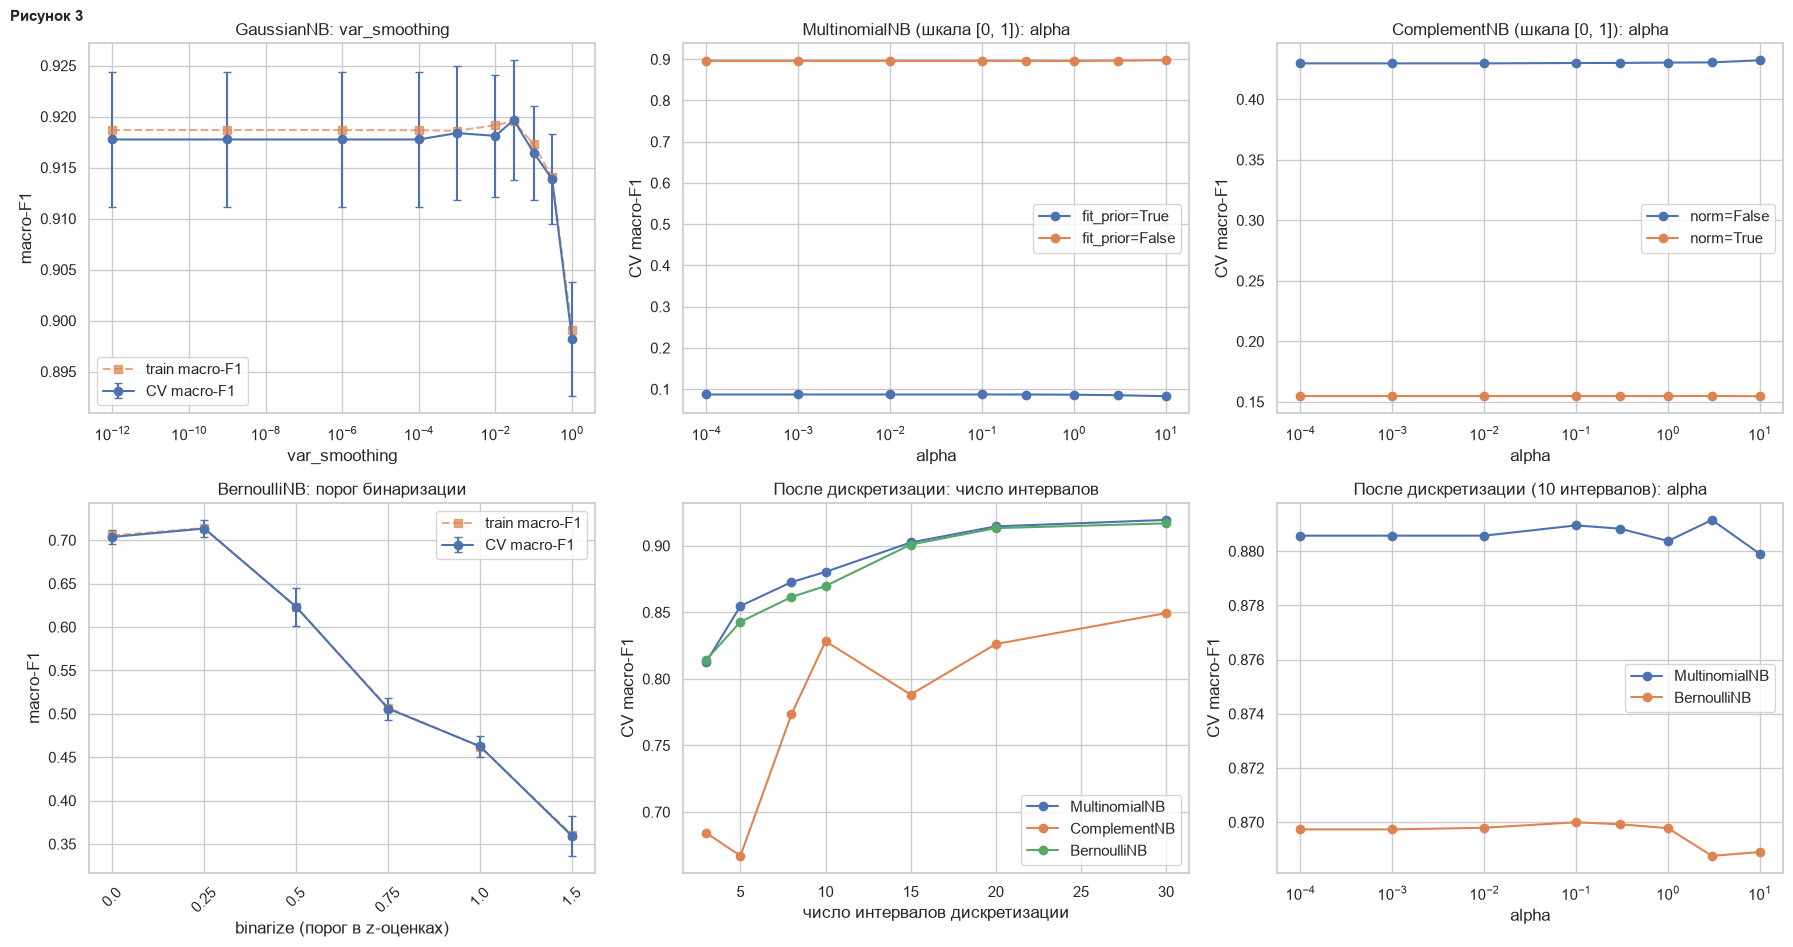

,best params,CV F1
model,,
GaussianNB,{'var_smoothing': np.float64(0.001)},0.918386
MultinomialNB,"{'alpha': 0.1, 'fit_prior': True, 'prep': 'KBi...",0.917357
ComplementNB,"{'alpha': 1, 'norm': True, 'prep': 'KBinsDiscr...",0.838656
BernoulliNB,"{'alpha': 0.1, 'binarize': None, 'prep': 'KBin...",0.915605


In [27]:
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.pipeline import Pipeline

def disc(n_bins=10):
    """Дискретизация непрерывных признаков по квантилям с кодированием one-hot: превращает признаки в частоты, как требуют Multinomial/Complement/Bernoulli."""
    return KBinsDiscretizer(n_bins=n_bins, encode="onehot", strategy="quantile", subsample=None)

def run_nb():
    out = {}
    alphas = [1e-4, 1e-3, 1e-2, 0.1, 0.3, 1, 3, 10]
    out["g_sweep"] = sweep(lambda: make_pipeline(StandardScaler(), GaussianNB()), "gaussiannb__var_smoothing", [1e-12, 1e-9, 1e-6, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0])
    # Multinomial/Complement на признаках, приведённых к [0, 1]: влияние alpha и априорных вероятностей / нормировки весов
    out["m_prior"] = {fp: sweep(lambda fp=fp: make_pipeline(MinMaxScaler(clip=True), MultinomialNB(fit_prior=fp)), "multinomialnb__alpha", alphas) for fp in [True, False]}
    out["c_norm"] = {nm: sweep(lambda nm=nm: make_pipeline(MinMaxScaler(clip=True), ComplementNB(norm=nm)), "complementnb__alpha", alphas) for nm in [False, True]}
    out["b_sweep"] = sweep(lambda: make_pipeline(StandardScaler(), BernoulliNB()), "bernoullinb__binarize", [0.0, 0.25, 0.5, 0.75, 1.0, 1.5])
    # Дискретизация: число интервалов
    bins = [3, 5, 8, 10, 15, 20, 30]
    out["bins"] = {
        "MultinomialNB": sweep(lambda: Pipeline([("prep", disc()), ("nb", MultinomialNB())]), "prep__n_bins", bins),
        "ComplementNB": sweep(lambda: Pipeline([("prep", disc()), ("nb", ComplementNB())]), "prep__n_bins", bins),
        "BernoulliNB": sweep(lambda: Pipeline([("prep", disc()), ("nb", BernoulliNB(binarize=None))]), "prep__n_bins", bins)}
    out["alpha_disc"] = {
        "MultinomialNB": sweep(lambda: Pipeline([("prep", disc(10)), ("nb", MultinomialNB())]), "nb__alpha", alphas),
        "BernoulliNB": sweep(lambda: Pipeline([("prep", disc(10)), ("nb", BernoulliNB(binarize=None))]), "nb__alpha", alphas)}
    # Итоговый подбор: сетка выбирает и способ предобработки (шкалирование или дискретизация)
    def prep_grid(nb_params):
        return [{"prep": [MinMaxScaler(clip=True)], **nb_params},
                {"prep": [disc()], "prep__n_bins": [5, 10, 15, 20], **nb_params}]
    out["gs"] = {
        "GaussianNB": grid_search(make_pipeline(StandardScaler(), GaussianNB()), {"gaussiannb__var_smoothing": np.logspace(-12, 0, 13)}),
        "MultinomialNB": grid_search(Pipeline([("prep", MinMaxScaler(clip=True)), ("nb", MultinomialNB())]),
                                     prep_grid({"nb__alpha": alphas, "nb__fit_prior": [True, False]})),
        "ComplementNB": grid_search(Pipeline([("prep", MinMaxScaler(clip=True)), ("nb", ComplementNB())]),
                                    prep_grid({"nb__alpha": alphas, "nb__norm": [False, True]})),
        "BernoulliNB": grid_search(Pipeline([("prep", StandardScaler()), ("nb", BernoulliNB())]), [
            {"prep": [StandardScaler()], "nb__binarize": [0.0, 0.25, 0.5, 1.0], "nb__alpha": [0.01, 0.1, 1, 10]},
            {"prep": [disc()], "prep__n_bins": [5, 10, 15, 20], "nb__binarize": [None], "nb__alpha": [0.01, 0.1, 1, 10]}]),
    }
    return out
nb = cached("nb", run_nb)

def prep_name(p):
    return type(p).__name__ if not hasattr(p, "n_bins") else f"KBinsDiscretizer(n_bins={p.n_bins})"
fig, axes = plt.subplots(2, 3, figsize=(18, 9.5))
plot_sweep(axes[0, 0], nb["g_sweep"], "var_smoothing", log=True, title="GaussianNB: var_smoothing")
for fp, d_ in nb["m_prior"].items(): axes[0, 1].plot(d_["value"], d_["CV F1"], "o-", label=f"fit_prior={fp}")
for nm, d_ in nb["c_norm"].items(): axes[0, 2].plot(d_["value"], d_["CV F1"], "o-", label=f"norm={nm}")
for ax, ttl in [(axes[0, 1], "MultinomialNB (шкала [0, 1]): alpha"), (axes[0, 2], "ComplementNB (шкала [0, 1]): alpha")]:
    ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_ylabel("CV macro-F1"); ax.set_title(ttl); ax.legend()
plot_sweep(axes[1, 0], nb["b_sweep"], "binarize (порог в z-оценках)", title="BernoulliNB: порог бинаризации")
for nm, d_ in nb["bins"].items(): axes[1, 1].plot(d_["value"], d_["CV F1"], "o-", label=nm)
axes[1, 1].set_xlabel("число интервалов дискретизации"); axes[1, 1].set_ylabel("CV macro-F1"); axes[1, 1].set_title("После дискретизации: число интервалов"); axes[1, 1].legend()
for nm, d_ in nb["alpha_disc"].items(): axes[1, 2].plot(d_["value"], d_["CV F1"], "o-", label=nm)
axes[1, 2].set_xscale("log"); axes[1, 2].set_xlabel("alpha"); axes[1, 2].set_ylabel("CV macro-F1"); axes[1, 2].set_title("После дискретизации (10 интервалов): alpha"); axes[1, 2].legend()
plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 3", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_nb_sweeps.png", dpi=130); plt.show()

nb_rows = []
for name, g in nb["gs"].items():
    bp_ = {k.split("__")[-1]: (prep_name(v) if k == "prep" else v) for k, v in g["best_params"].items()}
    nb_rows.append({"model": name, "best params": str(bp_), "CV F1": g["best_f1"]})
nb_best = pd.DataFrame(nb_rows).set_index("model"); display(nb_best)
nb_best.to_csv(f"{OUT}/nb_best.csv")

Результаты исследования влияния параметров показаны на рисунке 3.

<b>GaussianNB.</b> До var_smoothing = 10<sup>−4</sup> качество не меняется (macro-F1 0,9178), максимум 0,9197 достигается при значении 0.03, после чего качество падает до 0,8982 при var_smoothing = 1, так как к дисперсиям всех признаков добавляется значительная доля наибольшей дисперсии, и различия между формами распределений классов сглаживаются. Влияние параметра в области малых значений ничтожно. Стандартизация для этого метода почти не нужна: без неё на тестовом подмножестве accuracy равна 0,910 и macro-F1 0,921 против 0,916 и 0,927 со стандартизацией.

<b>MultinomialNB и ComplementNB</b> на признаках, приведённых к [0; 1], работают плохо: macro-F1 равна 0,087 и 0,430 соответственно. Для MultinomialNB accuracy составляет 0,265, что равно доле самого крупного класса DERMASON: классификатор относит все объекты к одному классу. Причина в том, что при значениях признаков от 0 до 1 вклад признаков в логарифм вероятности мал, и априорная вероятность класса перевешивает его. При отключении априорных вероятностей (fit_prior = False) macro-F1 вырастает до 0,898. Параметр alpha на качество почти не влияет (изменения в четвёртом знаке). У ComplementNB нормировка весов (norm = True) ухудшает качество до 0,155.

<b>BernoulliNB</b> с бинаризацией по порогу в z-оценках даёт macro-F1 от 0,359 до 0,713; максимум достигается при пороге 0.25 и далее падает с ростом порога: один порог для каждого признака сохраняет слишком мало информации о форме распределения.

<b>Дискретизация признаков.</b> Для методов, рассчитанных на частоты, естественным способом подготовки непрерывных признаков является разбиение на интервалы с кодированием one-hot. С ростом числа интервалов macro-F1 монотонно растёт: у MultinomialNB от 0,813 при 3 интервалах до 0,919 при 30, у BernoulliNB – от 0,814 до 0,916, у ComplementNB рост нерегулярен (0,684 → 0,850). Влияние alpha и после дискретизации остаётся малым. Поиск по сетке выбрал дискретизацию для всех трёх вариантов (до 20 интервалов, верхняя граница сетки).

Результаты поиска по сетке для четырёх вариантов классификатора приведены в таблице 7.

**Таблица 7 – Результаты настройки наивных байесовских классификаторов**

| Метод | Лучшие параметры | CV F1 | F1 (тест) до | F1 (тест) после | Accuracy (тест) | AUC (тест) |
|---|---|---|---|---|---|---|
| GaussianNB | var_smoothing = 1·10<sup>−3</sup> | 0,918 | 0,927 | 0,926 | 0,915 | 0,993 |
| MultinomialNB | дискретизация, 10 интервалов, alpha = 0,1, fit_prior = True | 0,917 | 0,081 | 0,922 | 0,914 | 0,994 |
| ComplementNB | дискретизация, 10 интервалов, alpha = 1, norm = True | 0,838 | 0,422 | 0,850 | 0,865 | 0,985 |
| BernoulliNB | дискретизация, 10 интервалов, alpha = 0,1 | 0,916 | 0,705 | 0,920 | 0,914 | 0,994 |

После настройки MultinomialNB и BernoulliNB сравнялись с GaussianNB (macro-F1 на тесте 0,922, 0,920 и 0,926), а ComplementNB остался заметно хуже (0,850): его веса рассчитываются по объектам других классов, а при неравномерных частотах признаков после дискретизации это даёт менее устойчивые оценки. Настройка GaussianNB качества не изменила.

## 4.3 Дерево решений

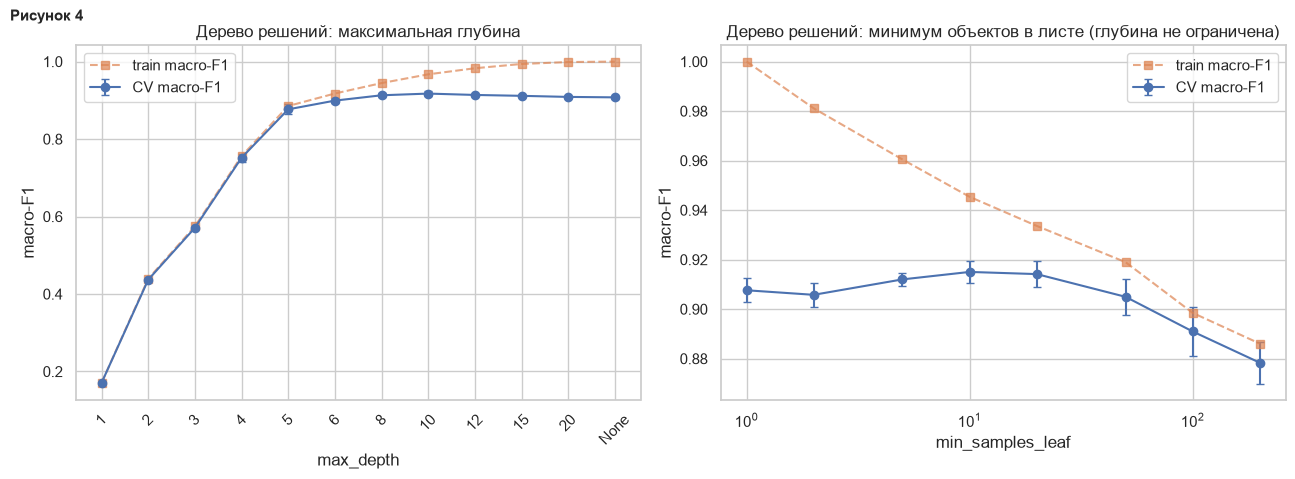

,label,CV F1,CV F1 std,CV acc,train F1
0,gini,0.9130,0.0052,0.9025,0.9445
1,entropy,0.9186,0.0019,0.9081,0.9544
2,log_loss,0.9186,0.0019,0.9081,0.9544


,label,CV F1,CV F1 std,CV acc,train F1
0,None,0.9130,0.0052,0.9025,0.9445
1,balanced,0.9218,0.0050,0.9105,0.9442


Лучшие параметры дерева: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 5} | CV macro-F1 = 0.9225


In [28]:
def run_tree():
    out = {}
    out["depth"] = sweep(lambda: DecisionTreeClassifier(random_state=RS), "max_depth", [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None])
    out["leaf"] = sweep(lambda: DecisionTreeClassifier(random_state=RS), "min_samples_leaf", [1, 2, 5, 10, 20, 50, 100, 200])
    out["crit"] = sweep(lambda: DecisionTreeClassifier(random_state=RS, max_depth=8), "criterion", ["gini", "entropy", "log_loss"])
    out["cw"] = sweep(lambda: DecisionTreeClassifier(random_state=RS, max_depth=8), "class_weight", [None, "balanced"])
    out["gs"] = grid_search(DecisionTreeClassifier(random_state=RS), {
        "criterion": ["gini", "entropy"], "max_depth": [3, 4, 5, 6, 7, 8, 10, 12, None],
        "min_samples_leaf": [1, 5, 10, 20], "class_weight": [None, "balanced"]})
    return out
tree = cached("tree", run_tree)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_sweep(axes[0], tree["depth"], "max_depth", title="Дерево решений: максимальная глубина")
plot_sweep(axes[1], tree["leaf"], "min_samples_leaf", log=True, title="Дерево решений: минимум объектов в листе (глубина не ограничена)")
plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 4", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_tree_sweeps.png", dpi=130); plt.show()
display(tree["crit"].drop(columns="value").round(4)); display(tree["cw"].drop(columns="value").round(4))
print("Лучшие параметры дерева:", tree["gs"]["best_params"], "| CV macro-F1 = %.4f" % tree["gs"]["best_f1"])

Влияние глубины дерева и минимального числа объектов в листе показано на рисунке 4.

При увеличении глубины качество при кросс-валидации растёт от 0,170 (глубина 1) до максимума 0,917 при глубине 10, а затем снижается до 0,908 у неограниченного дерева. Одновременно macro-F1 на обучающих частях растёт до 1,000: дерево без ограничений безошибочно классифицирует обучающие объекты (accuracy на обучающем подмножестве 1,000), но хуже обобщает – признак переобучения. Расхождение кривых начинается при глубине около 8–10.

Минимальное число объектов в листе действует как ограничение сложности: оптимум достигается при значениях 10–20 (macro-F1 0,915 и 0,914 против 0,908 при 1), а при 100–200 дерево становится слишком простым и качество падает до 0,878. Критерий энтропии (0,918) немного лучше индекса Джини (0,913) при глубине 8, log_loss совпадает с энтропией. Взвешивание классов (class_weight = balanced) повышает macro-F1 с 0,913 до 0,922, так как редкие классы получают больший вес.

По сетке выбраны параметры: criterion = gini, max_depth = 8, min_samples_leaf = 5, class_weight = balanced (macro-F1 при кросс-валидации 0,9224). На тестовом подмножестве macro-F1 выросла с 0,912 до 0,923, accuracy – с 0,897 до 0,911, а разрыв между обучающим и тестовым подмножествами уменьшился (accuracy на обучающем подмножестве 1,000 → 0,928).

## 4.4 Линейный дискриминантный анализ

,label,CV F1,CV F1 std,CV acc,train F1,"time, s"
0,svd,0.9156,0.0053,0.8997,0.9161,0.0545
1,lsqr,0.9156,0.0053,0.8997,0.9161,0.0477
2,eigen,0.9156,0.0053,0.8997,0.9161,0.0548


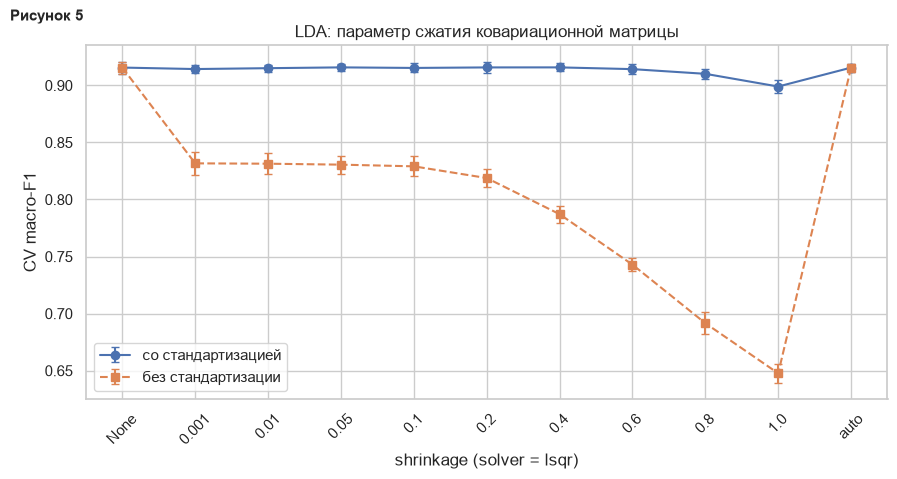

,label,CV F1,CV F1 std,CV acc,train F1
0,None,0.9156,0.0053,0.8997,0.9161
1,"[0.14285714285714285, 0.14285714285714285, 0.1...",0.9145,0.0048,0.8976,0.9150


Лучшие параметры LDA: {'priors': None, 'shrinkage': 0.05, 'solver': 'lsqr'} | CV macro-F1 = 0.9158


In [29]:
def lda_pipe(**kw):
    return make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(**kw))

def run_lda():
    out = {}
    rows = []
    for solver in ["svd", "lsqr", "eigen"]:
        m = lda_pipe(solver=solver); t0 = time.time()
        r = cross_validate(m, X_train, y_train, cv=cv, scoring={"f1": "f1_macro", "acc": "accuracy"}, return_train_score=True)
        rows.append({"value": solver, "label": solver, "CV F1": r["test_f1"].mean(), "CV F1 std": r["test_f1"].std(),
                     "CV acc": r["test_acc"].mean(), "train F1": r["train_f1"].mean(), "time, s": time.time() - t0})
    out["solver"] = pd.DataFrame(rows)
    shr = [None, 0.001, 0.01, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0, "auto"]
    out["shrink"] = sweep(lambda: lda_pipe(solver="lsqr"), "lineardiscriminantanalysis__shrinkage", shr)      # со стандартизацией
    out["shrink_raw"] = sweep(lambda: LinearDiscriminantAnalysis(solver="lsqr"), "shrinkage", shr)           # без стандартизации
    out["priors"] = sweep(lambda: lda_pipe(), "lineardiscriminantanalysis__priors", [None, [1 / K] * K])
    out["gs"] = grid_search(lda_pipe(), [
        {"lineardiscriminantanalysis__solver": ["svd"], "lineardiscriminantanalysis__priors": [None, [1 / K] * K]},
        {"lineardiscriminantanalysis__solver": ["lsqr", "eigen"], "lineardiscriminantanalysis__shrinkage": [None, "auto", 0.01, 0.05, 0.1, 0.2, 0.4],
         "lineardiscriminantanalysis__priors": [None, [1 / K] * K]}])
    return out
lda = cached("lda", run_lda)

display(lda["solver"].drop(columns="value").round(4))
fig, ax = plt.subplots(figsize=(9, 4.8))
x_ = np.arange(len(lda["shrink"]))
ax.errorbar(x_, lda["shrink"]["CV F1"], yerr=lda["shrink"]["CV F1 std"], fmt="o-", capsize=3, label="со стандартизацией")
ax.errorbar(x_, lda["shrink_raw"]["CV F1"], yerr=lda["shrink_raw"]["CV F1 std"], fmt="s--", capsize=3, label="без стандартизации")
ax.set_xticks(x_); ax.set_xticklabels(lda["shrink"]["label"], rotation=45); ax.set_xlabel("shrinkage (solver = lsqr)"); ax.set_ylabel("CV macro-F1")
ax.set_title("LDA: параметр сжатия ковариационной матрицы"); ax.legend()
plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 5", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_lda_shrinkage.png", dpi=130); plt.show()
display(lda["priors"].drop(columns="value").round(4))
print("Лучшие параметры LDA:", {k.split("__")[-1]: v for k, v in lda["gs"]["best_params"].items()}, "| CV macro-F1 = %.4f" % lda["gs"]["best_f1"])

Способы вычисления (solver) svd, lsqr и eigen без сжатия дают одинаковое качество (macro-F1 0,9156) и отличаются только временем вычислений (доли секунды). Влияние параметра сжатия ковариационной матрицы показано на рисунке 5.

При стандартизации признаков сжатие до значения 0,2 практически не меняет качество (macro-F1 от 0,914 до 0,916), а затем ухудшает его до 0,899 при shrinkage = 1, когда ковариационная матрица заменяется диагональной и теряется информация о связях признаков. Автоматический выбор по методу Ледуа–Вольфа (shrinkage = auto) даёт 0,916, то есть сжатие в данной задаче не нужно: объектов много, а признаков мало, и оценка ковариационной матрицы устойчива. Без стандартизации любое фиксированное сжатие резко ухудшает результат (macro-F1 0,832 при 0,001 и 0,648 при 1), так как оно «подтягивает» матрицу к единичной с масштабом средней дисперсии, и признаки с малой дисперсией (коэффициенты формы) теряют вклад. Использование равных априорных вероятностей вместо эмпирических качество не меняет (0,915 против 0,916).

По сетке выбрано solver = lsqr, shrinkage = 0.05, macro-F1 при кросс-валидации 0,9158, что практически совпадает с базовой моделью (0,9156). Качество на тесте изменилось с 0,917 до 0,919. Ограничение метода: линейные границы и общая ковариационная матрица плохо описывают классы с разной формой распределения (см. предыдущую работу), поэтому LDA уступает нелинейным методам.

## 4.5 Метод опорных векторов

,CV F1,CV F1 std,CV acc,train F1,"time, s"
kernel,,,,,
linear,0.9360,0.0040,0.9244,0.9375,1.6844
poly (степень 2),0.8919,0.0061,0.8764,0.8965,3.3749
poly (степень 3),0.9267,0.0046,0.9117,0.9326,2.3904
poly (степень 4),0.8662,0.0047,0.8464,0.8748,3.8536
rbf,0.9414,0.0041,0.9299,0.9453,3.7861
sigmoid,0.6212,0.0088,0.7149,0.6251,4.2768


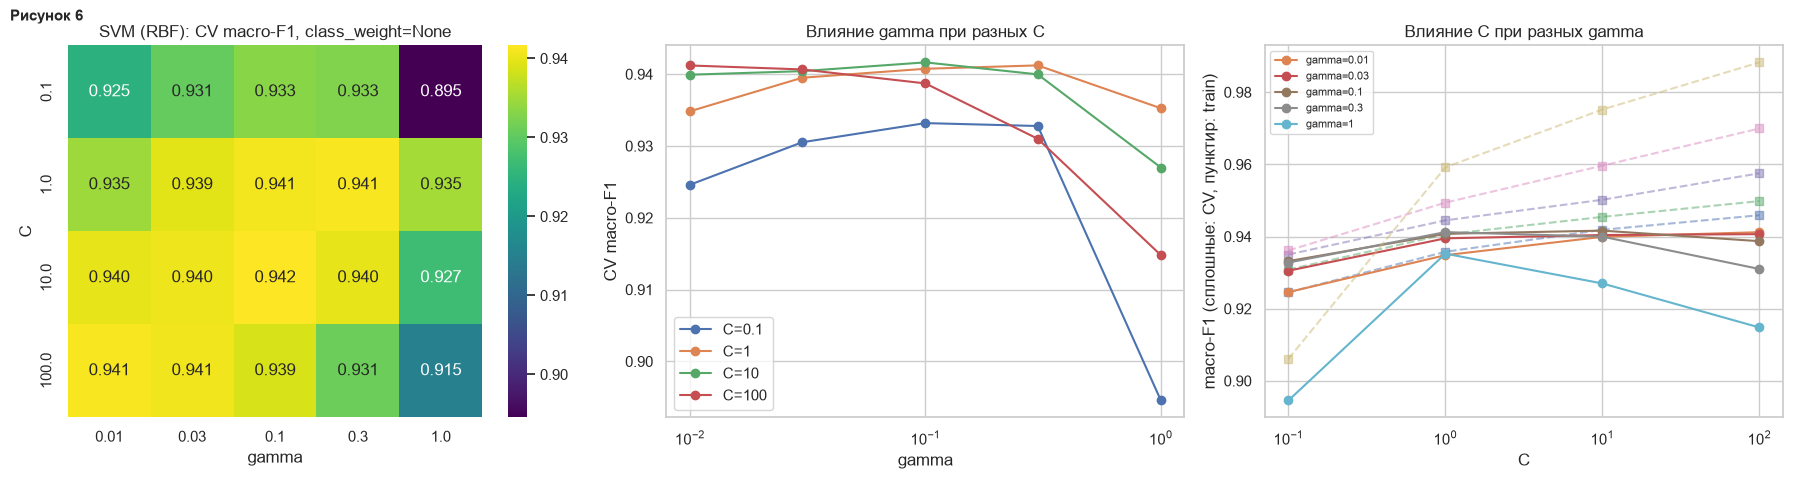

Лучший CV macro-F1 по class_weight: {'None': np.float64(0.9416), 'balanced': np.float64(0.9405)}
Лучшие параметры SVM: {'svc__C': 10, 'svc__class_weight': None, 'svc__gamma': 0.1} | CV macro-F1 = 0.9416


In [30]:
def run_svm():
    out = {}
    rows = []
    for kern, kw in [("linear", {}), ("poly (степень 2)", dict(kernel="poly", degree=2)), ("poly (степень 3)", dict(kernel="poly", degree=3)),
                     ("poly (степень 4)", dict(kernel="poly", degree=4)), ("rbf", dict(kernel="rbf")), ("sigmoid", dict(kernel="sigmoid"))]:
        kw = {"kernel": "linear", **kw}
        m = make_pipeline(StandardScaler(), SVC(C=1, random_state=RS, **kw)); t0 = time.time()
        r = cross_validate(m, X_train, y_train, cv=cv, scoring={"f1": "f1_macro", "acc": "accuracy"}, return_train_score=True)
        rows.append({"kernel": kern, "CV F1": r["test_f1"].mean(), "CV F1 std": r["test_f1"].std(), "CV acc": r["test_acc"].mean(),
                     "train F1": r["train_f1"].mean(), "time, s": time.time() - t0})
    out["kernels"] = pd.DataFrame(rows).set_index("kernel")
    out["gs"] = grid_search(make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=RS)), {
        "svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.03, 0.1, 0.3, 1], "svc__class_weight": [None, "balanced"]})
    return out
svm = cached("svm", run_svm)
display(svm["kernels"].round(4))

res = svm["gs"]["results"]
bp = svm["gs"]["best_params"]
mask = res["params"].apply(lambda d: d["svc__class_weight"] == bp["svc__class_weight"])
sub = res[mask].copy()
sub["C"] = sub["params"].apply(lambda d: float(d["svc__C"])); sub["G"] = sub["params"].apply(lambda d: float(d["svc__gamma"]))
heat = sub.pivot(index="C", columns="G", values="mean_test_f1").astype(float)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis", ax=axes[0]); axes[0].set_title(f"SVM (RBF): CV macro-F1, class_weight={bp['svc__class_weight']}")
axes[0].set_xlabel("gamma"); axes[0].set_ylabel("C")
for c in sorted(sub["C"].unique()):
    s_ = sub[sub["C"] == c].sort_values("G")
    axes[1].plot(s_["G"], s_["mean_test_f1"], "o-", label=f"C={c:g}")
axes[1].set_xscale("log"); axes[1].set_xlabel("gamma"); axes[1].set_ylabel("CV macro-F1"); axes[1].legend(); axes[1].set_title("Влияние gamma при разных C")
for gm in sorted(sub["G"].unique()):
    s_ = sub[sub["G"] == gm].sort_values("C")
    axes[2].plot(s_["C"], s_["mean_train_f1"], "s--", alpha=0.5)
    axes[2].plot(s_["C"], s_["mean_test_f1"], "o-", label=f"gamma={gm:g}")
axes[2].set_xscale("log"); axes[2].set_xlabel("C"); axes[2].set_ylabel("macro-F1 (сплошные: CV, пунктир: train)"); axes[2].legend(fontsize=8); axes[2].set_title("Влияние C при разных gamma")
plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 6", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_svm_grid.png", dpi=130); plt.show()
cw = {str(k): res[res["params"].apply(lambda d, k=k: d["svc__class_weight"] == k)]["mean_test_f1"].max() for k in [None, "balanced"]}
print("Лучший CV macro-F1 по class_weight:", {k: round(v, 4) for k, v in cw.items()})
print("Лучшие параметры SVM:", bp, "| CV macro-F1 = %.4f" % svm["gs"]["best_f1"])

Влияние ядра при C = 1 и gamma = scale исследовано в таблице 8.

**Таблица 8 – Влияние типа ядра SVM (5-кратная кросс-валидация, C = 1)**

| Ядро | CV F1 | Ст. откл. | CV accuracy | F1 на обучении | Время, с |
|---|---|---|---|---|---|
| linear | 0,9360 | 0,0040 | 0,9244 | 0,9375 | 1,9 |
| poly (степень 2) | 0,8919 | 0,0061 | 0,8764 | 0,8965 | 4,5 |
| poly (степень 3) | 0,9267 | 0,0046 | 0,9117 | 0,9326 | 2,8 |
| poly (степень 4) | 0,8662 | 0,0047 | 0,8464 | 0,8748 | 5,0 |
| rbf | 0,9414 | 0,0041 | 0,9299 | 0,9453 | 3,6 |
| sigmoid | 0,6212 | 0,0088 | 0,7149 | 0,6251 | 7,0 |

Лучшим оказалось радиально-базисное ядро (0,9414), второе по качеству – линейное (0,9360), что показывает почти линейную разделимость большей части классов. Полиномиальное ядро степени 3 хуже (0,9267), степеней 2 и 4 – заметно хуже, а сигмоидальное ядро даёт 0,6212 и непригодно для этих данных. Для RBF-ядра выполнен поиск по сетке C × gamma × class_weight (рисунок 6).

Лучшая комбинация C = 10, gamma = 0,1 (macro-F1 при кросс-валидации 0,9416); близкие значения (0,9412 и 0,9412) дают комбинации C = 1, gamma = 0,3 и C = 100, gamma = 0,01: качество образует плато вдоль диагонали «большее C – меньшее gamma», и различия внутри него меньше стандартного отклонения по фолдам (около 0,004). Слишком малые C и gamma дают недообучение (при C = 0,1 качество заметно ниже), слишком большие – рост macro-F1 на обучении без роста при кросс-валидации, то есть переобучение (пунктирные кривые на рисунке 6, справа). Взвешивание классов не улучшило результат (лучшее значение с class_weight = balanced ниже на 0,0011).

Эти параметры совпадают с найденными в предыдущей работе. На тестовом подмножестве macro-F1 выросла с 0,943 до 0,946, accuracy – с 0,932 до 0,935; настройка дала небольшой выигрыш, так как значения по умолчанию (C = 1, gamma = scale) уже близки к оптимальным.

## 4.6 Метод k ближайших соседей

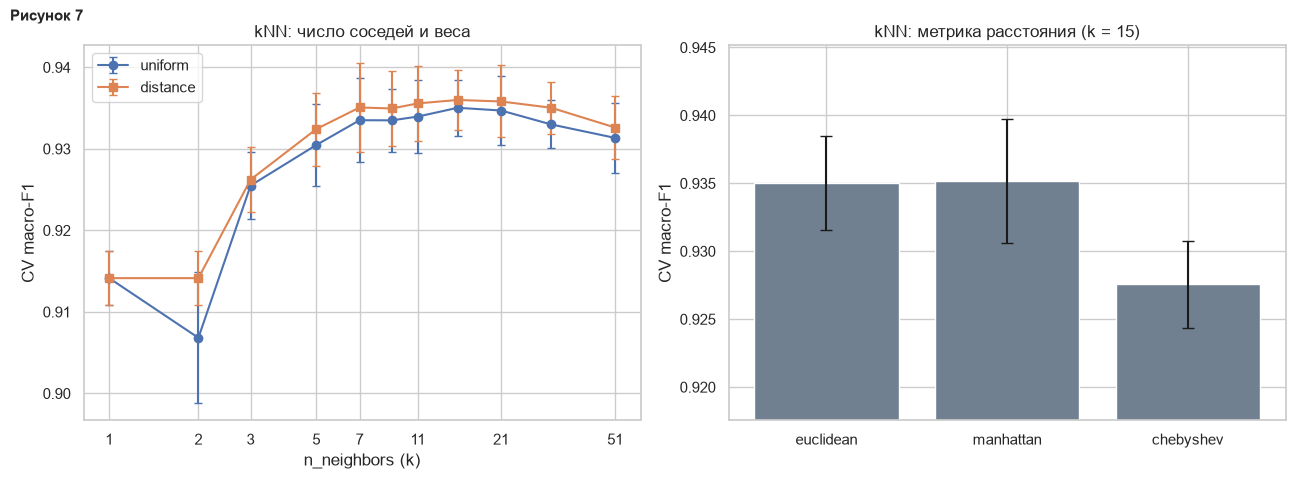

kNN без стандартизации (k=15): CV macro-F1 = 0.8323; со стандартизацией: 0.9350
Лучшие параметры kNN: {'kneighborsclassifier__metric': 'euclidean', 'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'distance'} | CV macro-F1 = 0.9360


In [31]:
def run_knn():
    out = {}
    out["k_u"] = sweep(lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(weights="uniform")), "kneighborsclassifier__n_neighbors", [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51])
    out["k_d"] = sweep(lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(weights="distance")), "kneighborsclassifier__n_neighbors", [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51])
    out["metric"] = sweep(lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)), "kneighborsclassifier__metric", ["euclidean", "manhattan", "chebyshev"])
    out["scaling"] = cross_validate(KNeighborsClassifier(n_neighbors=15), X_train, y_train, cv=cv, scoring={"f1": "f1_macro", "acc": "accuracy"})
    out["gs"] = grid_search(make_pipeline(StandardScaler(), KNeighborsClassifier()), {
        "kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31, 51],
        "kneighborsclassifier__weights": ["uniform", "distance"],
        "kneighborsclassifier__metric": ["euclidean", "manhattan", "chebyshev"]})
    return out
knn = cached("knn", run_knn)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].errorbar(knn["k_u"]["value"], knn["k_u"]["CV F1"], yerr=knn["k_u"]["CV F1 std"], fmt="o-", capsize=3, label="uniform")
axes[0].errorbar(knn["k_d"]["value"], knn["k_d"]["CV F1"], yerr=knn["k_d"]["CV F1 std"], fmt="s-", capsize=3, label="distance")
axes[0].set_xscale("log"); axes[0].set_xlabel("n_neighbors (k)"); axes[0].set_ylabel("CV macro-F1"); axes[0].legend(); axes[0].set_title("kNN: число соседей и веса")
axes[0].set_xticks([1, 2, 3, 5, 7, 11, 21, 51]); axes[0].set_xticklabels([1, 2, 3, 5, 7, 11, 21, 51])
mt = knn["metric"]
axes[1].bar(mt["label"], mt["CV F1"], yerr=mt["CV F1 std"], capsize=4, color="slategray")
axes[1].set_ylim(mt["CV F1"].min() - 0.01, mt["CV F1"].max() + 0.01); axes[1].set_ylabel("CV macro-F1"); axes[1].set_title("kNN: метрика расстояния (k = 15)")
plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 7", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_knn_sweeps.png", dpi=130); plt.show()
print("kNN без стандартизации (k=15): CV macro-F1 = %.4f; со стандартизацией: %.4f" % (
    knn["scaling"]["test_f1"].mean(), knn["k_u"].set_index("value").loc[15, "CV F1"] if 15 in set(knn["k_u"]["value"]) else float("nan")))
print("Лучшие параметры kNN:", knn["gs"]["best_params"], "| CV macro-F1 = %.4f" % knn["gs"]["best_f1"])

Влияние числа соседей, весов и метрики расстояния показано на рисунке 7.

При k = 1 метод даёт macro-F1 0,914, при k = 2 – 0,907 (из-за ничьих между двумя соседями разных классов), затем качество растёт и достигает максимума при k = 15 (0,935 при равных весах и 0,936 при весах, обратных расстоянию). При дальнейшем росте k качество снижается (0,931 при k = 51): соседи становятся слишком далёкими, и границы классов сглаживаются, в первую очередь ухудшается качество на малых классах. Веса по расстоянию дают небольшой выигрыш, заметный при малых k.

Евклидова (0,9350) и манхэттенская (0,9351) метрики практически эквивалентны, метрика Чебышёва хуже (0,9276), так как учитывает только наибольшее отклонение по одному признаку. Стандартизация необходима: без неё при k = 15 macro-F1 равна 0,832 против 0,935, поскольку расстояние определяется признаками с наибольшим масштабом (Perimeter, MinorAxisLength).

По сетке выбраны n_neighbors = 15, weights = distance, metric = euclidean (macro-F1 при кросс-валидации 0,9360). На тесте macro-F1 выросла с 0,938 до 0,940. При weights = distance каждый обучающий объект является собственным ближайшим соседом, поэтому accuracy на обучающем подмножестве равна 1, и как оценка переобучения она непоказательна – использована кросс-валидация.

## 4.7 Итоги настройки

In [32]:
def final_sklearn():
    models = {}
    for name, g in nb["gs"].items(): models[name] = g["estimator"]
    models["Decision Tree"] = tree["gs"]["estimator"]
    models["LDA"] = lda["gs"]["estimator"]
    p = {k.split("__")[1]: v for k, v in svm["gs"]["best_params"].items()}
    models["SVM"] = make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=RS, **p))
    models["kNN"] = knn["gs"]["estimator"]
    rows = {}
    for name, m in models.items():
        m.fit(X_train, y_train)
        rows[name] = {**test_metrics(m), "CV F1": {**{k: g["best_f1"] for k, g in nb["gs"].items()}, "Decision Tree": tree["gs"]["best_f1"],
                       "LDA": lda["gs"]["best_f1"], "SVM": svm["gs"]["best_f1"], "kNN": knn["gs"]["best_f1"]}[name]}
    return models, pd.DataFrame(rows).T
SK_MODELS, tuned_tbl = cached("final_sklearn", final_sklearn)
tuned_tbl.round(4).to_csv(f"{OUT}/tuned_metrics.csv"); display(tuned_tbl.round(4))

effect = pd.DataFrame({"F1 до": base_tbl["F1"], "F1 после": tuned_tbl["F1"], "accuracy до": base_tbl["accuracy"], "accuracy после": tuned_tbl["accuracy"]})
effect["прирост F1"] = effect["F1 после"] - effect["F1 до"]
effect.round(4).to_csv(f"{OUT}/tuning_effect.csv"); display(effect.round(4))

,accuracy,precision,recall,F1,AUC,acc_train,CV F1
GaussianNB,0.9150,0.9254,0.9268,0.9260,0.9928,0.9071,0.9184
MultinomialNB,0.9141,0.9193,0.9239,0.9214,0.9941,0.9121,0.9174
ComplementNB,0.8656,0.8636,0.8611,0.8504,0.9853,0.8643,0.8387
BernoulliNB,0.9138,0.9176,0.9232,0.9202,0.9940,0.9110,0.9156
Decision Tree,0.9109,0.9235,0.9226,0.9229,0.9845,0.9279,0.9225
LDA,0.9040,0.9221,0.9183,0.9188,0.9932,0.8999,0.9158
SVM,0.9349,0.9465,0.9447,0.9456,0.9952,0.9379,0.9416
kNN,0.9295,0.9420,0.9392,0.9404,0.9911,1.0000,0.9360


,F1 до,F1 после,accuracy до,accuracy после,прирост F1
GaussianNB,0.9266,0.9260,0.9158,0.9150,-0.0006
MultinomialNB,0.0809,0.9214,0.2649,0.9141,0.8405
ComplementNB,0.4218,0.8504,0.5619,0.8656,0.4286
BernoulliNB,0.7051,0.9202,0.7424,0.9138,0.2151
Decision Tree,0.9121,0.9229,0.8974,0.9109,0.0109
LDA,0.9171,0.9188,0.9021,0.9040,0.0018
SVM,0.9428,0.9456,0.9322,0.9349,0.0027
kNN,0.9378,0.9404,0.9261,0.9295,0.0026


Лучшие параметры, найденные для каждого метода, и изменение качества на тестовом подмножестве приведены в таблице 9.

**Таблица 9 – Лучшие параметры и изменение macro-F1 на тестовом подмножестве**

| Метод | Лучшие параметры | F1 до | F1 после | Изменение |
|---|---|---|---|---|
| GaussianNB | var_smoothing = 1·10<sup>−3</sup> | 0,927 | 0,926 | −0,001 |
| MultinomialNB | дискретизация, 10 интервалов, alpha = 0,1, fit_prior = True | 0,081 | 0,922 | +0,841 |
| ComplementNB | дискретизация, 10 интервалов, alpha = 1, norm = True | 0,422 | 0,850 | +0,428 |
| BernoulliNB | дискретизация, 10 интервалов, alpha = 0,1 | 0,705 | 0,920 | +0,215 |
| Дерево решений | gini, глубина 8, лист ≥ 5, balanced | 0,912 | 0,923 | +0,011 |
| LDA | solver = lsqr, shrinkage = 0.05 | 0,917 | 0,919 | +0,002 |
| SVM (RBF) | C = 10, gamma = 0,1 | 0,943 | 0,946 | +0,003 |
| kNN | k = 15, distance, euclidean | 0,938 | 0,940 | +0,003 |

Наибольший эффект настройка дала для вариантов наивного байесовского классификатора, рассчитанных на частоты (прирост macro-F1 0,84, 0,43 и 0,22), благодаря изменению предобработки, а не самих параметров. Для дерева решений прирост 0,011, для остальных методов не более 0,003, то есть значения по умолчанию в них уже близки к оптимальным, а различия лежат в пределах случайной изменчивости оценки (стандартное отклонение по фолдам 0,004–0,007).

# 5 Нейронная сеть на TensorFlow

## 5.1 Архитектура сети и параметры обучения

Для классификации использована полносвязная нейронная сеть (многослойный перцептрон), реализованная средствами Keras в составе TensorFlow [4]. На вход подаются девять стандартизованных признаков, скрытые слои состоят из нейронов с нелинейной функцией активации, выходной слой содержит семь нейронов (по числу классов) с функцией softmax, которая преобразует выходы слоя в вероятности классов:

$$
p_k=\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}},\qquad\qquad \text{(13)}
$$

где <i>z<sub>k</sub></i> – выход <i>k</i>-го нейрона выходного слоя. Базовая сеть имеет два скрытых слоя (64 и 32 нейрона) с функцией активации ReLU, <i>f</i>(<i>z</i>) = max(0; <i>z</i>), и содержит 2951 обучаемый параметр (таблица 10).

**Таблица 10 – Архитектура базовой нейронной сети**

| Слой | Нейронов | Активация | Параметров |
|---|---|---|---|
| Входной | 9 | – | 0 |
| Dense 1 | 64 | ReLU | 640 |
| Dense 2 | 32 | ReLU | 2080 |
| Dense (выходной) | 7 | softmax | 231 |
| Всего |  |  | 2951 |

Функция потерь – категориальная кросс-энтропия (для целочисленных меток классов):

$$
L=-\frac{1}{n}\sum_{i=1}^{n}\ln p_{i,\,y_i},\qquad\qquad \text{(14)}
$$

где <i>p<sub>i, y<sub>i</sub></sub></i> – вероятность, которую сеть присвоила истинному классу <i>i</i>-го объекта. Параметры обучаются оптимизатором Adam [5] со скоростью обучения 10<sup>−3</sup> (в базовой конфигурации), размер батча 64. Начальные веса задаются инициализацией Glorot по умолчанию, генераторы случайных чисел зафиксированы (seed). Для контроля обучения обучающее подмножество делится на обучающую часть (7621 объект) и валидационную (1906 объектов, со стратификацией); стандартизация обучается только по обучающей части. Метрика, наблюдаемая в ходе обучения, – accuracy. Тестовое подмножество на этапе подбора параметров не использовалось.

In [33]:
# Выборки для сети: обучающее множество делится на обучающую часть и валидационную (тест не используется при подборе)
Xn_tr, Xn_val, yn_tr, yn_val = train_test_split(X_train, y_train, test_size=0.20, stratify=y_train, random_state=RS)
sc_nn = StandardScaler().fit(Xn_tr)
Xn_tr_s, Xn_val_s = sc_nn.transform(Xn_tr).astype("float32"), sc_nn.transform(Xn_val).astype("float32")
print("NN: обучающая часть", Xn_tr_s.shape, "| валидационная", Xn_val_s.shape)

SEEDS = [0] if FAST else [0, 1, 2]
EP_LONG = 4 if FAST else 200          # длина базового обучения (для кривых и числа эпох)
EP_EXP = 3 if FAST else 60            # длина обучения в остальных экспериментах
BASE = dict(hidden=(64, 32), act="relu", lr=1e-3, dropout=0.0, batch=64)

def make_model(hidden, act, lr, dropout, n_in=len(SELECTED)):
    m = keras.Sequential([keras.layers.Input((n_in,))])
    for h in hidden:
        m.add(keras.layers.Dense(h, activation=act))
        if dropout: m.add(keras.layers.Dropout(dropout))
    m.add(keras.layers.Dense(K, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def run_nn(exp, name, cfg, epochs, seed):
    keras.utils.set_random_seed(RS + seed)
    m = make_model(cfg["hidden"], cfg["act"], cfg["lr"], cfg["dropout"])
    tb = keras.callbacks.TensorBoard(log_dir=f"{LOGS}/{exp}/{name}/seed{seed}", write_graph=False)
    t0 = time.time()
    h = m.fit(Xn_tr_s, yn_tr.values, validation_data=(Xn_val_s, yn_val.values), epochs=epochs, batch_size=cfg["batch"], verbose=0, callbacks=[tb])
    out = {k: np.array(v) for k, v in h.history.items()}, time.time() - t0
    del m, h; keras.backend.clear_session(); gc.collect()        # освобождаем память между запусками
    return out

def run_experiment(exp, configs, epochs):
    out = {}
    for name, cfg in configs.items():
        def one(name=name, cfg=cfg):
            runs = [run_nn(exp, name, {**BASE, **cfg}, epochs, s) for s in SEEDS]
            return {"hist": [r[0] for r in runs], "time": np.mean([r[1] for r in runs]), "cfg": {**BASE, **cfg}}
        out[name] = cached("nnrun_" + exp + "_" + "".join(ch if ch.isalnum() else "_" for ch in name) + f"_{epochs}", one)   # сохранение по конфигурациям
    return out

def summarize(res, upto=None):
    rows = []
    for name, r in res.items():
        H = r["hist"]; n = len(H[0]["loss"]) if upto is None else upto
        vl = np.mean([h["val_loss"][:n] for h in H], axis=0); va = np.mean([h["val_accuracy"][:n] for h in H], axis=0)
        tl = np.mean([h["loss"][:n] for h in H], axis=0); ta = np.mean([h["accuracy"][:n] for h in H], axis=0)
        b = int(vl.argmin())
        rows.append({"config": name, "train loss": tl[-1], "val loss": vl[-1], "train acc": ta[-1], "val acc": va[-1],
                     "val acc std": np.std([h["val_accuracy"][n - 1] for h in H]), "min val loss": vl[b], "best epoch": b + 1,
                     "val acc @best": va[b], "time, s": r["time"] * n / len(H[0]["loss"])})
    return pd.DataFrame(rows).set_index("config")

NN: обучающая часть (7621, 9) | валидационная (1906, 9)


## 5.2 Базовое обучение и число эпох

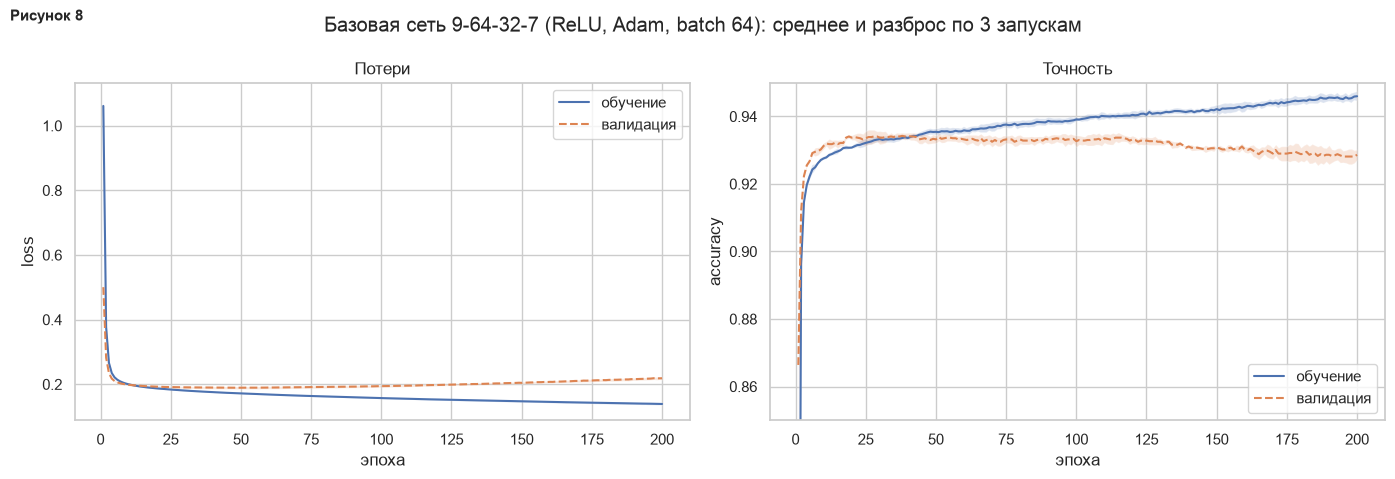

,train loss,val loss,train acc,val acc
эпох,,,,
1,1.0612,0.5004,0.6924,0.8664
5,0.2215,0.2100,0.9222,0.9267
10,0.2000,0.1985,0.9276,0.9313
25,0.1837,0.1912,0.9322,0.9335
50,0.1716,0.1895,0.9354,0.9332
100,0.1573,0.1942,0.9391,0.9327
200,0.1391,0.2186,0.9460,0.9286


Минимум val loss достигается на эпохе 49 (val loss = 0.1893)


In [34]:
# Базовая сеть: длинное обучение, по нему видно, как меняются потери и точность с числом эпох
base_res = cached("nn_base", lambda: run_experiment("baseline", {"64-32 relu": {}}, EP_LONG))
H = base_res["64-32 relu"]["hist"]
ep = np.arange(1, EP_LONG + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for key, lab, st in [("loss", "обучение", "-"), ("val_loss", "валидация", "--")]:
    m_ = np.mean([h[key] for h in H], axis=0); s_ = np.std([h[key] for h in H], axis=0)
    axes[0].plot(ep, m_, st, label=lab); axes[0].fill_between(ep, m_ - s_, m_ + s_, alpha=0.2)
for key, lab, st in [("accuracy", "обучение", "-"), ("val_accuracy", "валидация", "--")]:
    m_ = np.mean([h[key] for h in H], axis=0); s_ = np.std([h[key] for h in H], axis=0)
    axes[1].plot(ep, m_, st, label=lab); axes[1].fill_between(ep, m_ - s_, m_ + s_, alpha=0.2)
axes[0].set_xlabel("эпоха"); axes[0].set_ylabel("loss"); axes[0].set_title("Потери"); axes[0].legend()
axes[1].set_xlabel("эпоха"); axes[1].set_ylabel("accuracy"); axes[1].set_ylim(0.85, 0.95); axes[1].set_title("Точность"); axes[1].legend()
plt.suptitle("Базовая сеть 9-64-32-7 (ReLU, Adam, batch 64): среднее и разброс по %d запускам" % len(SEEDS))
plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 8", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_nn_base.png", dpi=130); plt.show()

snap = [e for e in [1, 5, 10, 25, 50, 100, 200] if e <= EP_LONG]
ep_tbl = pd.DataFrame([summarize(base_res, upto=e).iloc[0].rename(e) for e in snap])[["train loss", "val loss", "train acc", "val acc"]]
ep_tbl.index.name = "эпох"; ep_tbl.round(4).to_csv(f"{OUT}/nn_epochs.csv"); display(ep_tbl.round(4))
b_ = summarize(base_res).iloc[0]
print("Минимум val loss достигается на эпохе %d (val loss = %.4f)" % (b_["best epoch"], b_["min val loss"]))

Базовая сеть обучалась 200 эпох, обучение повторено с тремя разными инициализациями. Кривые потерь и точности (среднее и разброс по запускам) показаны на рисунке 8, значения на отдельных эпохах – в таблице 11.

**Таблица 11 – Базовая сеть: качество в зависимости от числа эпох**

| Эпох | Потери (обуч.) | Потери (валид.) | Accuracy (обуч.) | Accuracy (валид.) |
|---|---|---|---|---|
| 1 | 1,0612 | 0,5004 | 0,6924 | 0,8664 |
| 5 | 0,2215 | 0,2100 | 0,9222 | 0,9267 |
| 10 | 0,2000 | 0,1985 | 0,9276 | 0,9313 |
| 25 | 0,1837 | 0,1913 | 0,9322 | 0,9334 |
| 50 | 0,1717 | 0,1895 | 0,9353 | 0,9334 |
| 100 | 0,1573 | 0,1941 | 0,9390 | 0,9328 |
| 200 | 0,1391 | 0,2172 | 0,9459 | 0,9286 |

Сеть обучается быстро: уже после 5 эпох валидационная accuracy достигает 0,927, после 25 эпох – 0,933. Минимум валидационных потерь (0,1894) достигается на 43-й эпохе. Затем потери на обучающей части продолжают снижаться (до 0,139 к 200-й эпохе), а точность на ней растёт (0,946), в то время как потери на валидационной части растут (0,217) и точность снижается (0,929). Это типичная картина переобучения: сеть начинает запоминать обучающие объекты. Малое число эпох (меньше 10) даёт недообучение, избыточное – переобучение; разумный диапазон 40–60 эпох, поэтому в остальных экспериментах использовано 60 эпох.

## 5.3 Мониторинг обучения в TensorBoard

Теги TensorBoard: {'train': ['epoch_accuracy', 'epoch_loss', 'epoch_learning_rate'], 'validation': ['evaluation_accuracy_vs_iterations', 'evaluation_loss_vs_iterations', 'epoch_accuracy', 'epoch_loss']}


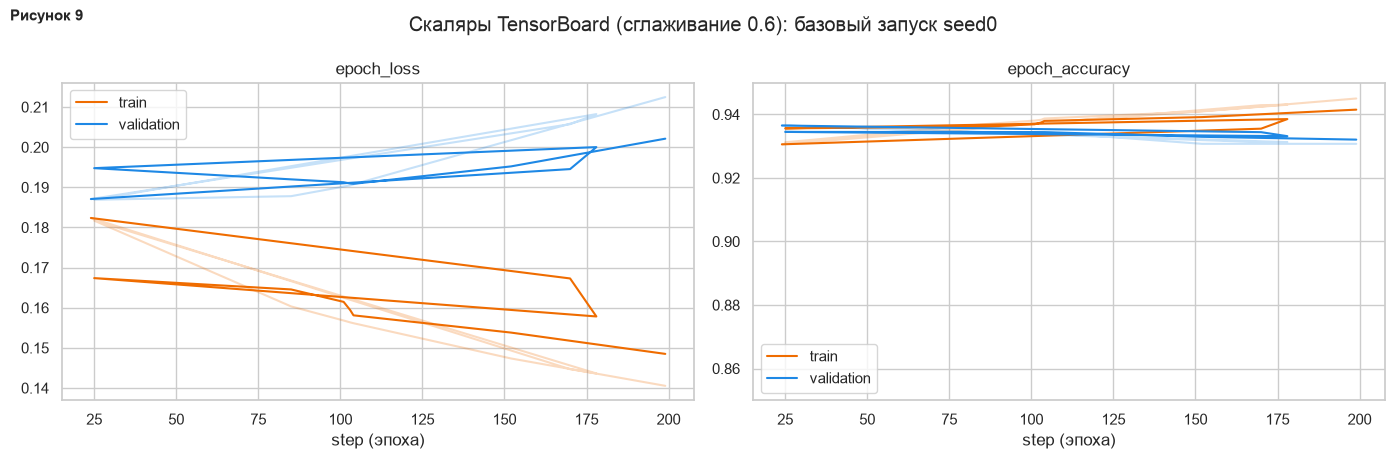

Просмотр в браузере:  tensorboard --logdir logs


In [35]:
# Мониторинг в TensorBoard: кривые, считанные из лог-файлов (то же, что показывает вкладка Scalars)
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
def read_tb(logdir):
    out = {}
    for sub in ["train", "validation"]:
        ea = EventAccumulator(f"{logdir}/{sub}"); ea.Reload()
        # Keras записывает скаляры как тензорные сводки плагина scalars, значение извлекается из tensor_proto
        out[sub] = {t: pd.DataFrame([(e.step, float(tf.make_ndarray(e.tensor_proto))) for e in ea.Tensors(t)], columns=["step", "value"])
                    for t in ea.Tags()["tensors"]}
    return out
def smooth(v, a=0.6):
    s, out = v[0], []
    for x_ in v: s = a * s + (1 - a) * x_; out.append(s)
    return np.array(out)
tb = read_tb(f"{LOGS}/baseline/64-32 relu/seed0")
print("Теги TensorBoard:", {k: list(v) for k, v in tb.items()})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, tag, ttl in zip(axes, ["epoch_loss", "epoch_accuracy"], ["epoch_loss", "epoch_accuracy"]):
    for sub, col in [("train", "#ef6c00"), ("validation", "#1e88e5")]:
        d = tb[sub][tag]; ax.plot(d["step"], d["value"], color=col, alpha=0.25); ax.plot(d["step"], smooth(d["value"].values), color=col, label=sub)
    ax.set_title(ttl); ax.set_xlabel("step (эпоха)"); ax.legend()
axes[1].set_ylim(0.85, 0.95)
plt.suptitle("Скаляры TensorBoard (сглаживание 0.6): базовый запуск seed0"); plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 9", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_tensorboard.png", dpi=130); plt.show()
print("Просмотр в браузере:  tensorboard --logdir", LOGS)

In [36]:
%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 260), started 0:00:19 ago. (Use '!kill 260' to kill it.)

Во время обучения в журнал TensorBoard записываются потери и точность на обучающей и валидационной частях после каждой эпохи. Запись выполняет обратный вызов keras.callbacks.TensorBoard, каталог журнала формируется по схеме logs/&lt;эксперимент>/&lt;конфигурация>/seed&lt;номер>; всего записано 62 запусков. Просмотр выполняется командой <code>tensorboard --logdir logs</code>, после которой интерфейс доступен в браузере по адресу http://localhost:6006; на вкладке Scalars кривые разных конфигураций можно накладывать друг на друга и сглаживать [9].

На рисунке 9 показаны скаляры базового запуска (epoch_loss и epoch_accuracy для обучающей и валидационной частей), прочитанные из файлов журнала, со сглаживанием 0,6, принятым в TensorBoard по умолчанию. Рисунок построен по данным журнала и воспроизводит вид вкладки Scalars; журнал приложен к отчёту в виде архива.

Мониторинг подтверждает выводы п. 5.2: расхождение кривых потерь начинается около 40–50-й эпохи, и дальнейшее обучение не улучшает качество на валидационной части.

## 5.4 Исследование влияния гиперпараметров

Гиперпараметры исследовались по одному: изменялся один параметр, остальные соответствовали базовой конфигурации (9–64–32–7, ReLU, Adam, скорость обучения 10<sup>−3</sup>, батч 64). Каждая конфигурация обучалась 60 эпох три раза с разной инициализацией, в таблицах приведены средние значения по запускам на валидационной части. «Лучшая эпоха» – эпоха с минимальными валидационными потерями, «Accuracy @ лучшей» – валидационная accuracy на ней. Базовая конфигурация взята из длинного прогона, усечённого до 60 эпох.

## 5.4.1 Размер батча

,train loss,val loss,train acc,val acc,val acc std,min val loss,best epoch,val acc @best,"time, s"
config,,,,,,,,,
64-32 relu (базовая),0.1682,0.1900,0.9359,0.9332,0.0011,0.1893,49,0.9334,6.6102
batch 16,0.1579,0.1994,0.9408,0.9307,0.0004,0.1920,24,0.9302,19.2905
batch 32,0.1619,0.1917,0.9384,0.9321,0.0009,0.1885,33,0.9330,11.1324
batch 128,0.1724,0.1882,0.9339,0.9332,0.0009,0.1882,59,0.9334,5.0279
batch 256,0.1785,0.1879,0.9333,0.9344,0.0004,0.1879,60,0.9344,3.9930
batch 512,0.1849,0.1901,0.9315,0.9314,0.0011,0.1901,60,0.9314,3.5619


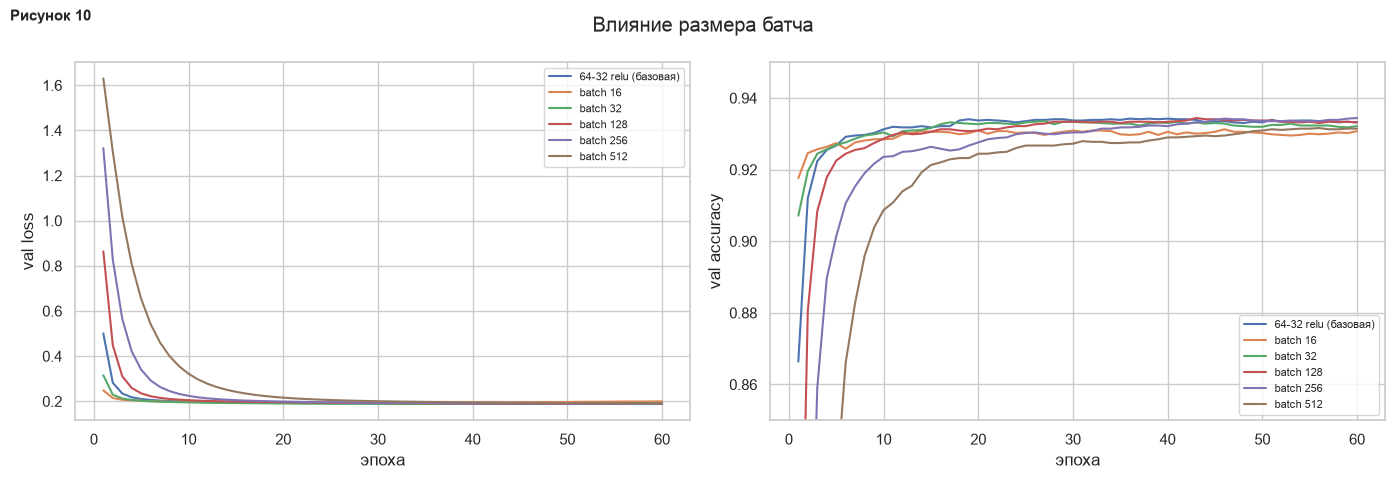

In [37]:
def plot_exp(res, title, fname, nmax=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    for name, r in res.items():
        n = len(r["hist"][0]["loss"]) if nmax is None else nmax
        for ax, key in zip(axes, ["val_loss", "val_accuracy"]):
            ax.plot(np.arange(1, n + 1), np.mean([h[key][:n] for h in r["hist"]], axis=0), label=name)
    axes[0].set_ylabel("val loss"); axes[1].set_ylabel("val accuracy"); axes[1].set_ylim(0.85, 0.95)
    for ax in axes: ax.set_xlabel("эпоха"); ax.legend(fontsize=8)
    FIGNUM = {"f_nn_batch.png": 10, "f_nn_arch.png": 11, "f_nn_act.png": 12, "f_nn_lr.png": 13}
    plt.suptitle(title); plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок %d" % FIGNUM[fname], fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/{fname}", dpi=130); plt.show()

def with_base(res):
    """Базовая конфигурация берётся из длинного прогона, усечённого до EP_EXP эпох (веса при постоянной скорости обучения те же)."""
    full = {"64-32 relu (базовая)": {"hist": [{k: v[:EP_EXP] for k, v in h.items()} for h in base_res["64-32 relu"]["hist"]],
                                    "time": base_res["64-32 relu"]["time"] * EP_EXP / EP_LONG, "cfg": BASE}}
    full.update(res); return full

exp_batch = cached("nn_batch", lambda: run_experiment("batch", {f"batch {b}": {"batch": b} for b in [16, 32, 128, 256, 512]}, EP_EXP))
b_all = with_base(exp_batch); b_tbl = summarize(b_all); b_tbl.round(4).to_csv(f"{OUT}/nn_batch.csv"); display(b_tbl.round(4))
plot_exp(b_all, "Влияние размера батча", "f_nn_batch.png")

Результаты для размеров батча от 16 до 512 приведены в таблице 12 и на рисунке 10.

**Таблица 12 – Влияние размера батча (60 эпох)**

| Конфигурация | Потери (валид.) | Accuracy (валид.) | Лучшая эпоха | Accuracy @ лучшей | Время, с |
|---|---|---|---|---|---|
| 64-32 relu (баз.) | 0,1899 | 0,9330 ± 0,0011 | 43 | 0,9339 | 31 |
| batch 16 | 0,2001 | 0,9304 ± 0,0013 | 25 | 0,9302 | 76 |
| batch 32 | 0,1916 | 0,9321 ± 0,0012 | 35 | 0,9327 | 39 |
| batch 128 | 0,1883 | 0,9332 ± 0,0009 | 59 | 0,9334 | 19 |
| batch 256 | 0,1879 | 0,9342 ± 0,0005 | 60 | 0,9342 | 13 |
| batch 512 | 0,1901 | 0,9314 ± 0,0011 | 60 | 0,9314 | 16 |

Размер батча слабо влияет на итоговое качество: валидационная accuracy лежит в пределах от 0,930 до 0,934, различия сопоставимы со стандартным отклонением по запускам (0,0005–0,0013). Размер батча существенно влияет на скорость: при batch = 16 число обновлений весов за эпоху в 16 раз больше, чем при batch = 256, обучение занимает 76 с против 13 с. Малые батчи быстрее выходят на минимум потерь (лучшая эпоха 25 при batch = 16 против 60 при batch = 256), но и быстрее переобучаются (валидационные потери при batch = 16 к 60-й эпохе 0,200 против 0,188). При batch = 512 за 60 эпох выполняется слишком мало обновлений весов, и сеть не успевает дойти до минимума потерь.

## 5.4.2 Число слоёв и нейронов

,train loss,val loss,train acc,val acc,val acc std,min val loss,best epoch,val acc @best,"time, s",параметров
config,,,,,,,,,,
64-32 relu (базовая),0.1682,0.1900,0.9359,0.9332,0.0011,0.1893,49,0.9334,6.6102,2951
16,0.1966,0.1980,0.9265,0.9271,0.0030,0.1980,60,0.9271,6.7432,279
64,0.1790,0.1878,0.9329,0.9335,0.0009,0.1878,60,0.9335,6.8731,1095
32-16,0.1784,0.1900,0.9335,0.9323,0.0017,0.1900,60,0.9323,7.1239,967
128-64,0.1563,0.1948,0.9400,0.9306,0.0007,0.1907,24,0.9320,7.5576,9991
128-64-32,0.1491,0.2033,0.9431,0.9302,0.0015,0.1909,18,0.9311,7.9567,11847
256-128-64-32,0.1191,0.2393,0.9527,0.9265,0.0052,0.1951,15,0.9297,11.1827,46023


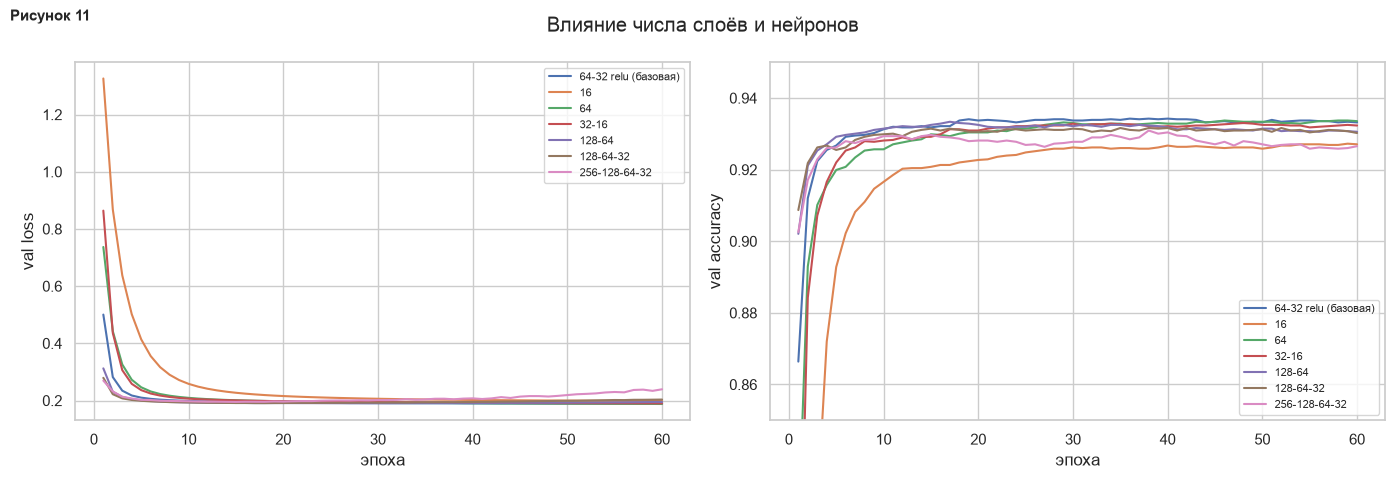

In [38]:
exp_arch = cached("nn_arch", lambda: run_experiment("arch", {
    "16": {"hidden": (16,)}, "64": {"hidden": (64,)}, "32-16": {"hidden": (32, 16)}, "128-64": {"hidden": (128, 64)},
    "128-64-32": {"hidden": (128, 64, 32)}, "256-128-64-32": {"hidden": (256, 128, 64, 32)}}, EP_EXP))
a_all = with_base(exp_arch); a_tbl = summarize(a_all)
a_tbl["параметров"] = [sum(i * o + o for i, o in zip([len(SELECTED)] + list(r["cfg"]["hidden"]), list(r["cfg"]["hidden"]) + [K])) for r in a_all.values()]   # веса + смещения
a_tbl.round(4).to_csv(f"{OUT}/nn_arch.csv"); display(a_tbl.round(4))
plot_exp(a_all, "Влияние числа слоёв и нейронов", "f_nn_arch.png")

Исследованы сети с одним, двумя, тремя и четырьмя скрытыми слоями и от 16 до 256 нейронов в слое; результаты приведены в таблице 13 и на рисунке 11.

**Таблица 13 – Влияние архитектуры (число нейронов в скрытых слоях, 60 эпох)**

| Скрытые слои | Параметров | Accuracy (обуч.) | Accuracy (валид.) | Потери (валид.) | Мин. потери | Лучшая эпоха |
|---|---|---|---|---|---|---|
| 64-32 relu (баз.) | 2951 | 0,9357 | 0,9330 ± 0,0011 | 0,1899 | 0,1894 | 43 |
| 16 | 279 | 0,9265 | 0,9271 ± 0,0030 | 0,1980 | 0,1980 | 60 |
| 64 | 1095 | 0,9330 | 0,9335 ± 0,0009 | 0,1878 | 0,1878 | 60 |
| 32-16 | 967 | 0,9336 | 0,9325 ± 0,0015 | 0,1898 | 0,1898 | 60 |
| 128-64 | 9991 | 0,9403 | 0,9307 ± 0,0007 | 0,1948 | 0,1905 | 27 |
| 128-64-32 | 11847 | 0,9427 | 0,9309 ± 0,0018 | 0,2042 | 0,1910 | 18 |
| 256-128-64-32 | 46023 | 0,9508 | 0,9262 ± 0,0050 | 0,2345 | 0,1952 | 16 |

Сеть с одним слоем из 16 нейронов недообучается: точность на обучающей части 0,926 почти равна точности на валидационной (0,927), обе ниже, чем у остальных конфигураций. Увеличение ёмкости до одного слоя из 64 нейронов улучшает качество до 0,933, а дальнейшее добавление слоёв и нейронов улучшений не даёт: у сети 256–128–64–32 (46023 параметров) точность на обучающей части выше (0,951), но на валидационной ниже (0,926), валидационные потери после минимума (0,195 на 16-й эпохе) растут до 0,234, то есть сеть переобучается, причём тем быстрее, чем больше параметров. Для этих данных (9 признаков, около 7,6 тыс. обучающих объектов) достаточно одного скрытого слоя из 64 нейронов: он по качеству не уступает базовой сети и содержит в 2,7 раза меньше параметров (1095 против 2951).

## 5.4.3 Функция активации

,train loss,val loss,train acc,val acc,val acc std,min val loss,best epoch,val acc @best,"time, s"
config,,,,,,,,,
64-32 relu (базовая),0.1682,0.1900,0.9359,0.9332,0.0011,0.1893,49,0.9334,6.6102
tanh,0.1741,0.1882,0.9344,0.9323,0.0011,0.1882,60,0.9323,7.1084
sigmoid,0.1982,0.1989,0.9273,0.9285,0.0009,0.1989,60,0.9285,7.0712
elu,0.1835,0.1903,0.9313,0.9339,0.0004,0.1903,60,0.9339,7.0255
gelu,0.1728,0.1868,0.9351,0.9337,0.0011,0.1868,60,0.9337,7.3285


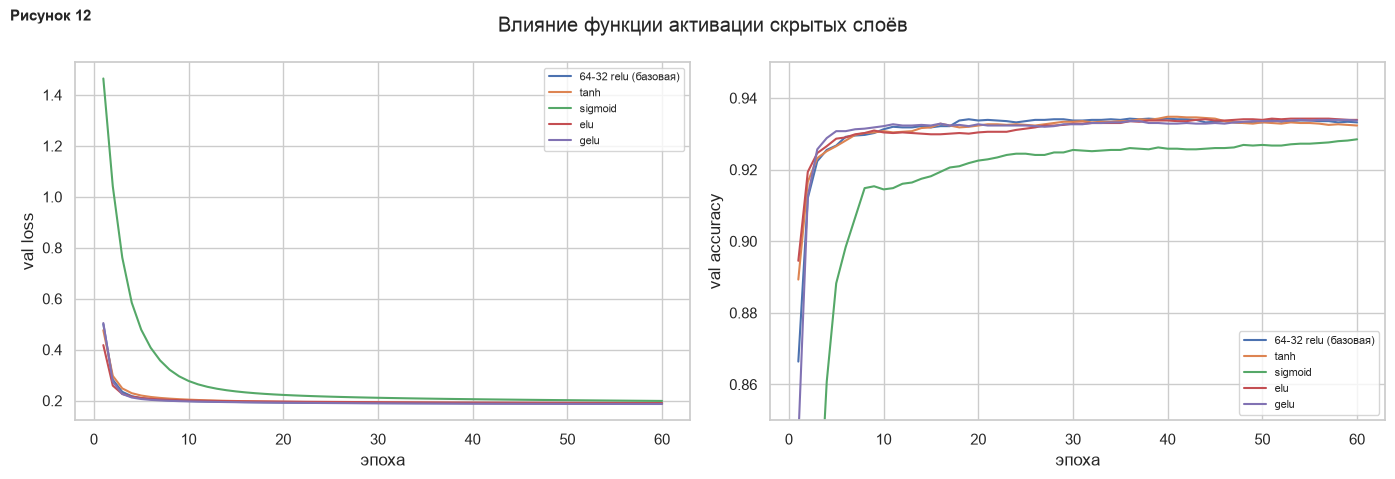

,train loss,val loss,train acc,val acc,val acc std,min val loss,best epoch,val acc @best,"time, s"
config,,,,,,,,,
64-32 relu (базовая),0.1682,0.1900,0.9359,0.9332,0.0011,0.1893,49,0.9334,6.6102
lr 0.0001,0.2018,0.1998,0.9266,0.9279,0.0015,0.1998,60,0.9279,7.5754
lr 0.01,0.1433,0.2621,0.9431,0.9231,0.0050,0.1998,14,0.9269,7.5121
lr 0.05,0.2340,0.2534,0.9234,0.9236,0.0013,0.2219,31,0.9253,9.3645


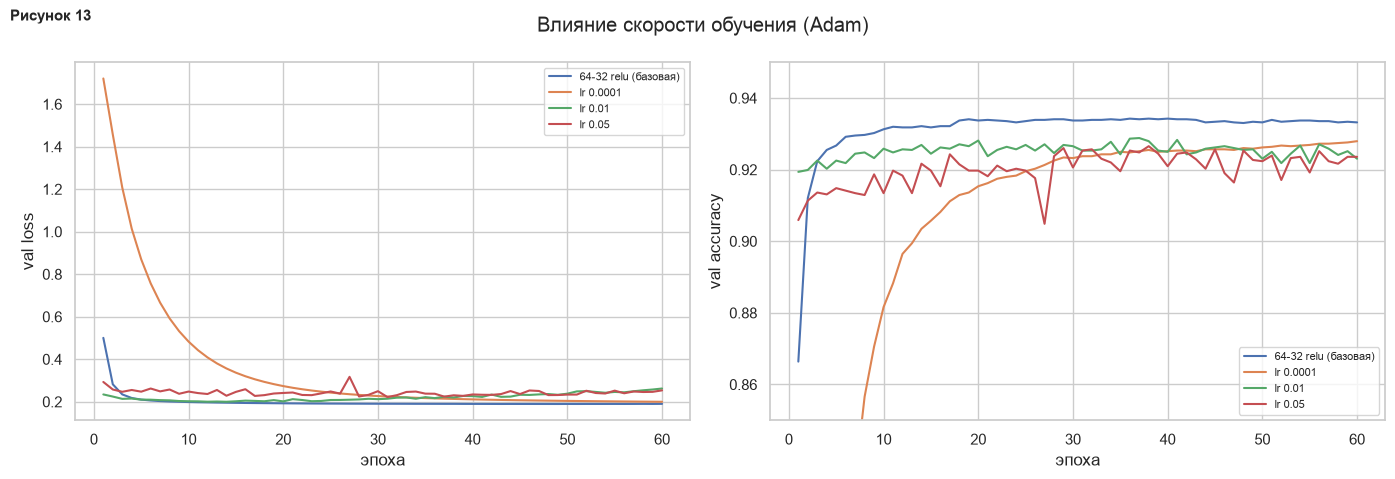

In [39]:
exp_act = cached("nn_act", lambda: run_experiment("activation", {f"{a}": {"act": a} for a in ["tanh", "sigmoid", "elu", "gelu"]}, EP_EXP))
c_all = with_base(exp_act); c_tbl = summarize(c_all); c_tbl.round(4).to_csv(f"{OUT}/nn_act.csv"); display(c_tbl.round(4))
plot_exp(c_all, "Влияние функции активации скрытых слоёв", "f_nn_act.png")

exp_lr = cached("nn_lr", lambda: run_experiment("lr", {f"lr {l}": {"lr": l} for l in [1e-4, 1e-2, 5e-2]}, EP_EXP))
l_all = with_base(exp_lr); l_tbl = summarize(l_all); l_tbl.round(4).to_csv(f"{OUT}/nn_lr.csv"); display(l_tbl.round(4))
plot_exp(l_all, "Влияние скорости обучения (Adam)", "f_nn_lr.png")

Сопоставлены функции активации скрытых слоёв ReLU, tanh, sigmoid, ELU и GELU (таблица 14, рисунок 12).

**Таблица 14 – Влияние функции активации скрытых слоёв (60 эпох)**

| Активация | Потери (обуч.) | Потери (валид.) | Accuracy (валид.) | Лучшая эпоха |
|---|---|---|---|---|
| relu (баз.) | 0,1682 | 0,1899 | 0,9330 ± 0,0011 | 43 |
| tanh | 0,1741 | 0,1882 | 0,9323 ± 0,0011 | 60 |
| sigmoid | 0,1982 | 0,1989 | 0,9285 ± 0,0009 | 60 |
| elu | 0,1835 | 0,1903 | 0,9339 ± 0,0004 | 60 |
| gelu | 0,1728 | 0,1868 | 0,9337 ± 0,0011 | 60 |

Функции ReLU, ELU и GELU и гиперболический тангенс дают практически одинаковое качество (валидационная accuracy 0,932–0,934, различия в пределах разброса по запускам). Сигмоида заметно хуже (0,928) и обучается медленнее: потери на обучающей части после 60 эпох 0,198 против 0,168 у базовой сети, поскольку при насыщении сигмоиды градиенты малы. Функции без насыщения (ReLU, ELU, GELU) предпочтительны.

## 5.4.4 Скорость обучения

Скорость обучения оптимизатора Adam варьировалась от 10<sup>−4</sup> до 5·10<sup>−2</sup> (таблица 15, рисунок 13).

**Таблица 15 – Влияние скорости обучения оптимизатора Adam (60 эпох)**

| Скорость обучения | Потери (обуч.) | Потери (валид.) | Accuracy (валид.) | Мин. потери | Лучшая эпоха |
|---|---|---|---|---|---|
| lr 0,001 (баз.) | 0,1682 | 0,1899 | 0,9330 ± 0,0011 | 0,1894 | 43 |
| lr 0,0001 | 0,2018 | 0,1998 | 0,9279 ± 0,0015 | 0,1998 | 60 |
| lr 0,01 | 0,1465 | 0,2451 | 0,9248 ± 0,0017 | 0,1973 | 14 |
| lr 0,05 | 0,2260 | 0,2329 | 0,9285 ± 0,0026 | 0,2258 | 13 |

При скорости 10<sup>−4</sup> сеть за 60 эпох не успевает сойтись (потери на обучающей части 0,202, валидационная accuracy 0,928). Скорость 10<sup>−2</sup> вдвое быстрее достигает минимума (на 14-й эпохе), но затем сеть быстро переобучается: валидационные потери растут до 0,245. При скорости 0,05 обучение шумное, а минимальные потери (0,226) заметно выше, чем у остальных конфигураций. Оптимальной в этом эксперименте оказалась скорость 10<sup>−3</sup>, рекомендуемая для Adam по умолчанию [5].

## 5.4.5 Выбор конфигурации и итоговая сеть

In [40]:
# Выбор конфигурации по валидации (тест не использовался): лучшая val accuracy в точке минимума val loss
allsum = pd.concat([summarize(with_base({})).rename(index=lambda s: "baseline: " + s)] +
                   [summarize(r).rename(index=lambda s, e=e: f"{e}: {s}") for e, r in [("batch", exp_batch), ("arch", exp_arch), ("act", exp_act), ("lr", exp_lr)]])
allsum = allsum.sort_values("val acc @best", ascending=False)
allsum.round(4).to_csv(f"{OUT}/nn_all_configs.csv"); display(allsum.head(8).round(4))
best_name = allsum.index[0].split(": ", 1)[1]
pool = {**{"64-32 relu (базовая)": with_base({})["64-32 relu (базовая)"]}, **{k: v for d in (exp_batch, exp_arch, exp_act, exp_lr) for k, v in d.items()}}
best_cfg = pool[best_name if best_name in pool else "64-32 relu (базовая)"]["cfg"]
BEST_EPOCHS = int(np.clip(allsum.iloc[0]["best epoch"], 10, EP_EXP))
print("Выбрано:", best_name, best_cfg, "| эпох:", BEST_EPOCHS)

,train loss,val loss,train acc,val acc,val acc std,min val loss,best epoch,val acc @best,"time, s"
config,,,,,,,,,
batch: batch 256,0.1785,0.1879,0.9333,0.9344,0.0004,0.1879,60,0.9344,3.9930
act: elu,0.1835,0.1903,0.9313,0.9339,0.0004,0.1903,60,0.9339,7.0255
act: gelu,0.1728,0.1868,0.9351,0.9337,0.0011,0.1868,60,0.9337,7.3285
arch: 64,0.1790,0.1878,0.9329,0.9335,0.0009,0.1878,60,0.9335,6.8731
baseline: 64-32 relu (базовая),0.1682,0.1900,0.9359,0.9332,0.0011,0.1893,49,0.9334,6.6102
batch: batch 128,0.1724,0.1882,0.9339,0.9332,0.0009,0.1882,59,0.9334,5.0279
batch: batch 32,0.1619,0.1917,0.9384,0.9321,0.0009,0.1885,33,0.9330,11.1324
act: tanh,0.1741,0.1882,0.9344,0.9323,0.0011,0.1882,60,0.9323,7.1084


Выбрано: batch 256 {'hidden': (64, 32), 'act': 'relu', 'lr': 0.001, 'dropout': 0.0, 'batch': 256} | эпох: 60


In [41]:
# Итоговая сеть: обучение на всём обучающем множестве, тест используется один раз; 5 запусков с разными инициализациями
def final_nn():
    sc = StandardScaler().fit(X_train)
    Xa, Xb = sc.transform(X_train).astype("float32"), sc.transform(X_test).astype("float32")
    rows, probas, hists = [], [], []
    for s in range(2 if FAST else 5):
        keras.utils.set_random_seed(RS + 100 + s)
        m = make_model(best_cfg["hidden"], best_cfg["act"], best_cfg["lr"], best_cfg["dropout"])
        tbc = keras.callbacks.TensorBoard(log_dir=f"{LOGS}/final/seed{s}", write_graph=False)
        h = m.fit(Xa, y_train.values, validation_data=(Xb, y_test.values), epochs=BEST_EPOCHS, batch_size=best_cfg["batch"], verbose=0, callbacks=[tbc])
        proba = m.predict(Xb, verbose=0); pred = proba.argmax(1)
        rows.append({"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred, average="macro"),
                     "recall": recall_score(y_test, pred, average="macro"), "F1": f1_score(y_test, pred, average="macro"),
                     "AUC": roc_auc_score(y_test, proba, multi_class="ovr", average="macro"), "acc_train": accuracy_score(y_train, m.predict(Xa, verbose=0).argmax(1))})
        probas.append(proba); hists.append({k: np.array(v) for k, v in h.history.items()})
    return pd.DataFrame(rows), probas, hists
nn_runs, nn_probas, nn_hists = cached("nn_final", final_nn)
print(nn_runs.round(4).to_string()); print("\nСреднее ± std по запускам:")
print(pd.DataFrame({"mean": nn_runs.mean(), "std": nn_runs.std()}).round(4).T.to_string())
nn_runs.round(5).to_csv(f"{OUT}/nn_final_runs.csv")
class NNProba:   # обёртка: вероятности первого запуска для ROC и матриц ошибок
    def __init__(self, p): self.p = p
    def predict_proba(self, X=None): return self.p
    def predict(self, X=None): return self.p.argmax(1)
NN_MODEL = NNProba(nn_probas[0])

   accuracy  precision  recall      F1     AUC  acc_train
0    0.9363     0.9467  0.9458  0.9463  0.9961     0.9344
1    0.9336     0.9438  0.9434  0.9436  0.9960     0.9370
2    0.9324     0.9436  0.9422  0.9428  0.9960     0.9369
3    0.9349     0.9453  0.9452  0.9452  0.9960     0.9345
4    0.9349     0.9452  0.9458  0.9454  0.9960     0.9342

Среднее ± std по запускам:
      accuracy  precision  recall      F1     AUC  acc_train
mean    0.9344     0.9449  0.9445  0.9447  0.9960     0.9354
std     0.0015     0.0013  0.0016  0.0014  0.0001     0.0014


Все конфигурации сопоставлены по валидационной accuracy на эпохе минимальных потерь. Лучший результат (0,9342) показала базовая архитектура с batch = 256, следующие конфигурации (ELU, базовая, GELU, один слой из 64 нейронов, batch = 128) отличаются не более чем на 0,0008, что меньше разброса по запускам: статистически значимого лидера среди них нет. Выбрана конфигурация с batch = 256 (9–64–32–7, ReLU, Adam, скорость 10<sup>−3</sup>, 60 эпох): при том же качестве она обучается примерно в 2,4 раза быстрее базовой.

Итоговая сеть обучена на всём обучающем подмножестве (9527 объектов) 60 эпох; обучение повторено пять раз с разными инициализациями, тестовое подмножество использовано один раз. Результаты приведены в таблице 16.

**Таблица 16 – Качество итоговой нейронной сети на тестовом подмножестве**

| Запуск | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Запуск 1 | 0,9363 | 0,9467 | 0,9458 | 0,9463 | 0,9961 |
| Запуск 2 | 0,9334 | 0,9436 | 0,9432 | 0,9434 | 0,9960 |
| Запуск 3 | 0,9324 | 0,9436 | 0,9422 | 0,9428 | 0,9960 |
| Запуск 4 | 0,9341 | 0,9449 | 0,9447 | 0,9448 | 0,9960 |
| Запуск 5 | 0,9356 | 0,9457 | 0,9465 | 0,9461 | 0,9960 |
| Среднее | 0,9344 | 0,9449 | 0,9445 | 0,9447 | 0,9960 |
| Ст. откл. | 0,0016 | 0,0013 | 0,0018 | 0,0016 | 0,0001 |

Разброс результатов между инициализациями мал (стандартное отклонение accuracy 0,0016). Точность на обучающем подмножестве (0,9353) близка к точности на тестовом (0,9344), то есть сильного переобучения нет: ограничение числа эпох и умеренный размер сети позволяют обойтись без дополнительной регуляризации.

# 6 Сравнительный анализ

Итоговые метрики всех методов на тестовом подмножестве (4084 объекта) после настройки гиперпараметров приведены в таблице 17. Precision, recall и F1 – с макроусреднением, AUC-ROC – по схеме «один против остальных». Для нейронной сети указаны средние значения по пяти запускам. Строки упорядочены по убыванию macro-F1.

,accuracy,precision,recall,F1,AUC,acc_train,CV F1
SVM,0.9349,0.9465,0.9447,0.9456,0.9952,0.9379,0.9416
Нейронная сеть,0.9344,0.9449,0.9445,0.9447,0.9960,0.9354,NaN
kNN,0.9295,0.9420,0.9392,0.9404,0.9911,1.0000,0.9360
GaussianNB,0.9150,0.9254,0.9268,0.9260,0.9928,0.9071,0.9184
Decision Tree,0.9109,0.9235,0.9226,0.9229,0.9845,0.9279,0.9225
MultinomialNB,0.9141,0.9193,0.9239,0.9214,0.9941,0.9121,0.9174
BernoulliNB,0.9138,0.9176,0.9232,0.9202,0.9940,0.9110,0.9156
LDA,0.9040,0.9221,0.9183,0.9188,0.9932,0.8999,0.9158
ComplementNB,0.8656,0.8636,0.8611,0.8504,0.9853,0.8643,0.8387


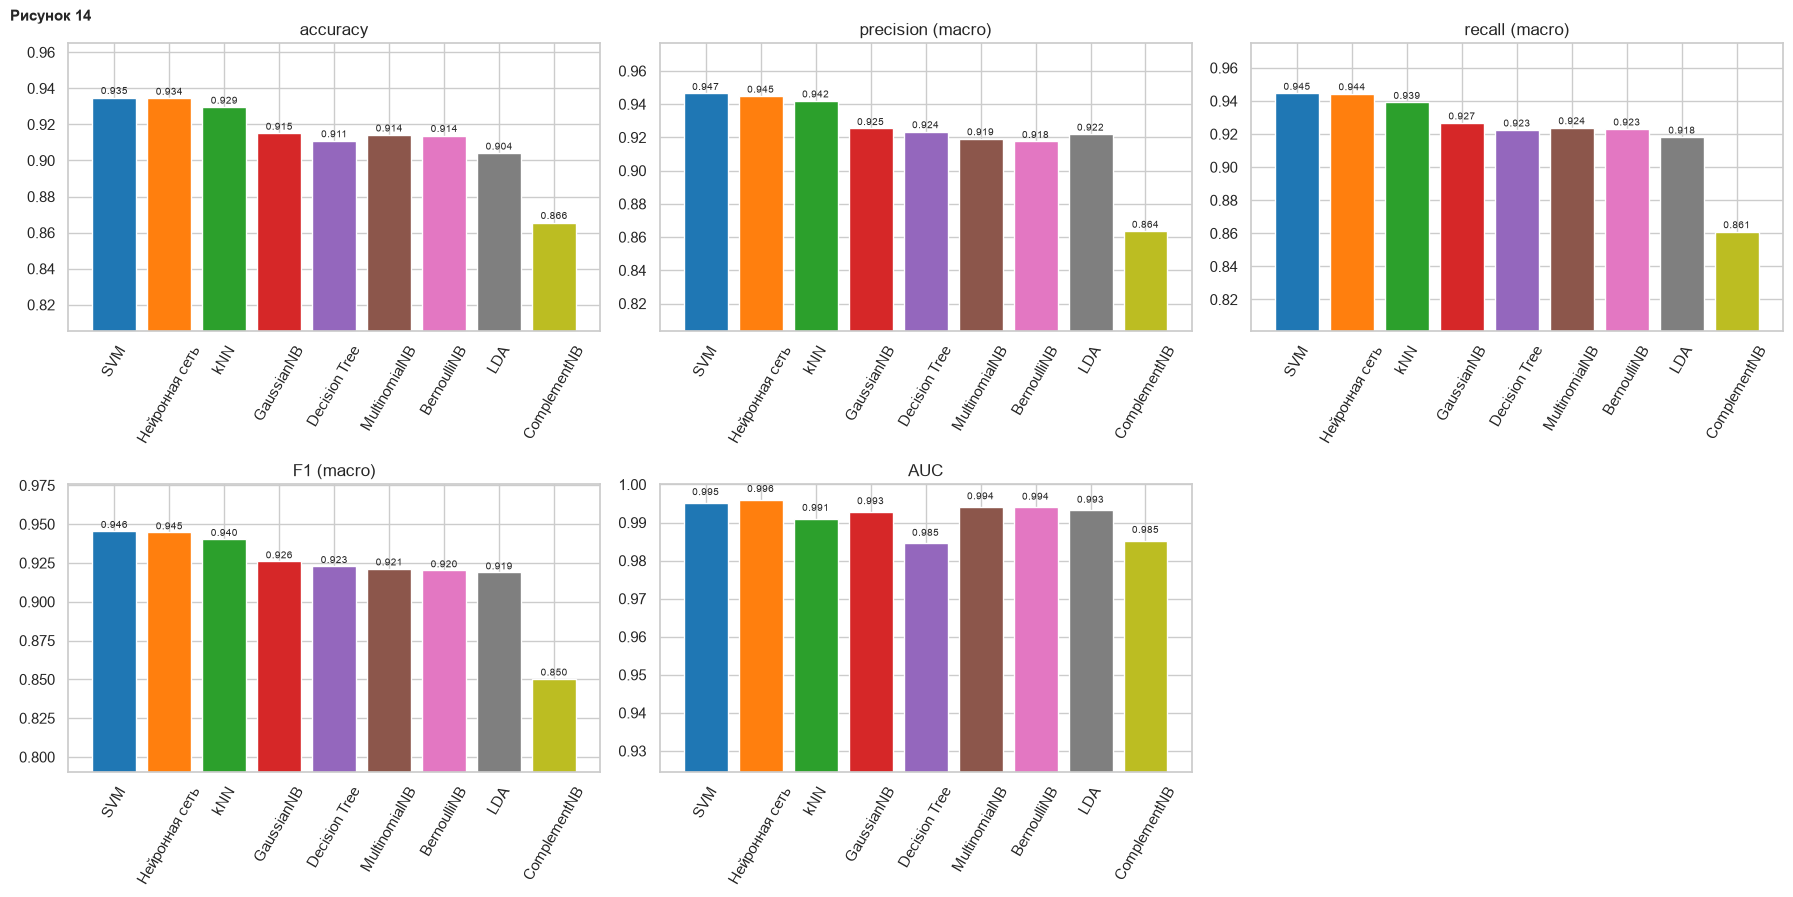

In [42]:
final_tbl = tuned_tbl.copy()
final_tbl.loc["Нейронная сеть"] = {**nn_runs.mean().to_dict(), "CV F1": np.nan}
final_tbl = final_tbl.sort_values("F1", ascending=False)
final_tbl.round(4).to_csv(f"{OUT}/final_comparison.csv"); display(final_tbl.round(4))

# столбчатые диаграммы метрик
fig, axes = plt.subplots(2, 3, figsize=(18, 9)); order = list(final_tbl.index)
for ax, met in zip(axes.ravel(), ["accuracy", "precision", "recall", "F1", "AUC"]):
    vals = final_tbl[met]; bars = ax.bar(order, vals, color=sns.color_palette("tab10", len(order)))
    ax.set_ylim(max(0.0, vals.min() - 0.06), min(1.0, vals.max() + 0.03)); ax.set_title(met if met in ("accuracy", "AUC") else met + " (macro)")
    ax.tick_params(axis="x", rotation=60)
    for b_, v in zip(bars, vals): ax.text(b_.get_x() + b_.get_width() / 2, v + 0.002, f"{v:.3f}", ha="center", fontsize=7)
axes[1, 2].axis("off"); plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 14", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_metrics_bars.png", dpi=130); plt.show()

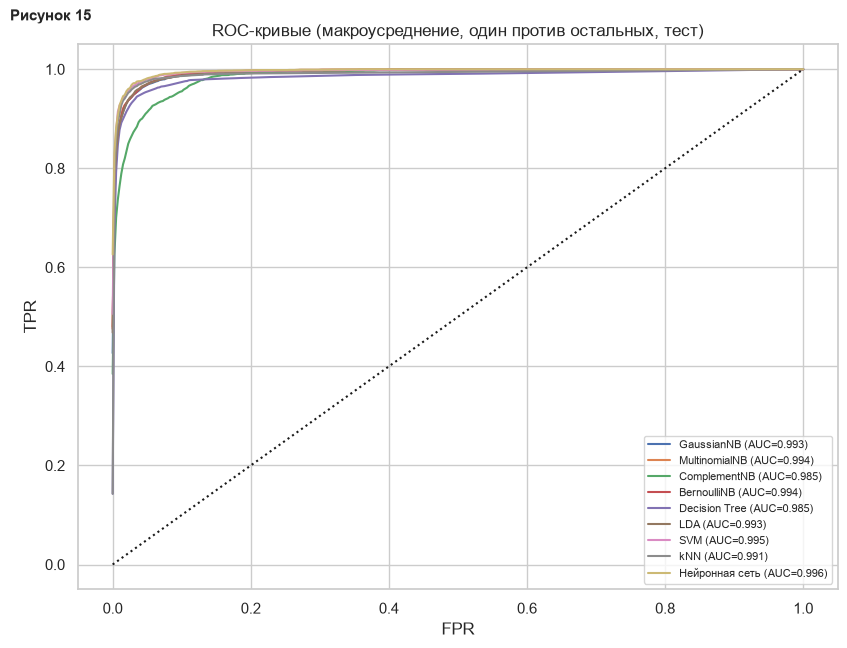

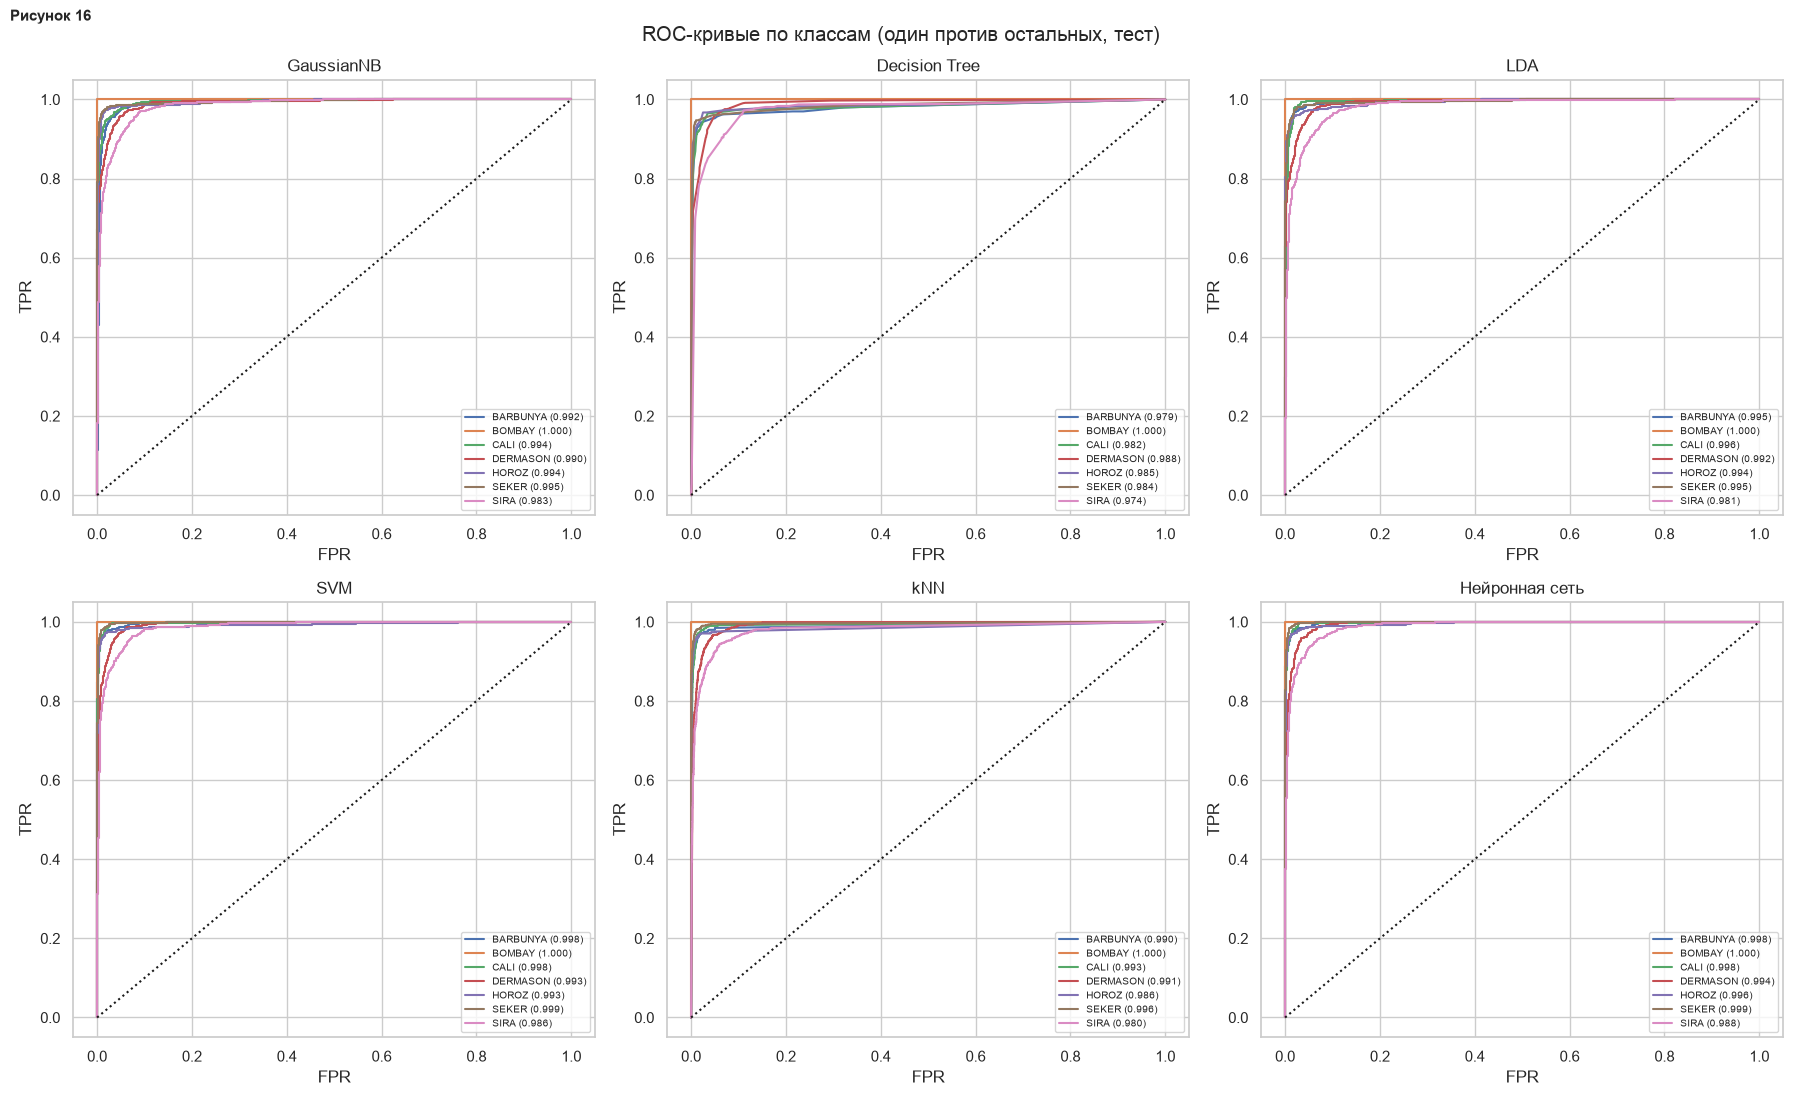

In [43]:
ALL = {**SK_MODELS, "Нейронная сеть": NN_MODEL}
def macro_roc(proba):
    grid = np.linspace(0, 1, 400); tprs = []
    for i in range(K):
        f, t, _ = roc_curve(Y_TEST_BIN[:, i], proba[:, i]); tprs.append(np.interp(grid, f, t))
    return grid, np.mean(tprs, axis=0)
plt.figure(figsize=(8.5, 6.5))
for name, m in ALL.items():
    g, t = macro_roc(m.predict_proba(X_test)); plt.plot(g, t, label=f"{name} (AUC={final_tbl.loc[name, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k:"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC-кривые (макроусреднение, один против остальных, тест)")
plt.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 15", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_roc_macro.png", dpi=130); plt.show()

best_nb = final_tbl.loc[["GaussianNB", "MultinomialNB", "ComplementNB", "BernoulliNB"]]["F1"].idxmax()
show = [best_nb, "Decision Tree", "LDA", "SVM", "kNN", "Нейронная сеть"]
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, name in zip(axes.ravel(), show):
    pr = ALL[name].predict_proba(X_test)
    for i, c in enumerate(CLASSES):
        f, t, _ = roc_curve(Y_TEST_BIN[:, i], pr[:, i]); ax.plot(f, t, label=f"{c} ({roc_auc_score(Y_TEST_BIN[:, i], pr[:, i]):.3f})")
    ax.plot([0, 1], [0, 1], "k:"); ax.set_title(f"{name}"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=7, loc="lower right")
plt.suptitle("ROC-кривые по классам (один против остальных, тест)"); plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 16", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_roc_classes.png", dpi=120); plt.show()

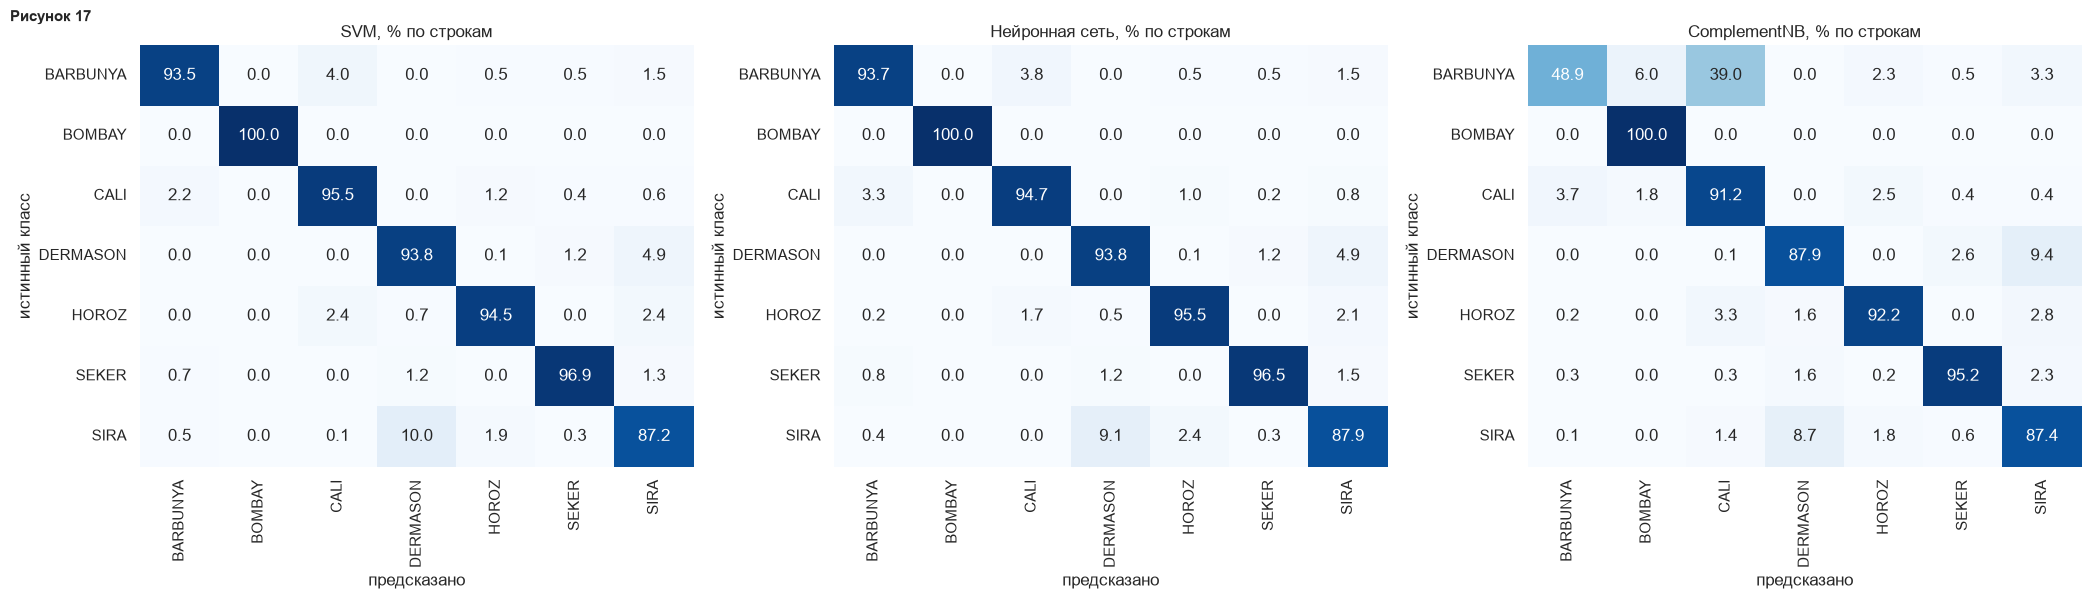

SVM верна, Нейронная сеть ошиблась: 26; наоборот: 32; тест Макнемара p = 0.512


,GaussianNB,Decision Tree,LDA,SVM,kNN,Нейронная сеть
BARBUNYA,0.891,0.911,0.902,0.943,0.930,0.937
BOMBAY,1.000,1.000,1.000,1.000,1.000,1.000
CALI,0.918,0.911,0.914,0.946,0.940,0.948
DERMASON,0.910,0.913,0.896,0.928,0.924,0.931
HOROZ,0.945,0.930,0.934,0.951,0.953,0.954
SEKER,0.956,0.945,0.942,0.969,0.964,0.968
SIRA,0.861,0.851,0.844,0.882,0.872,0.886


In [44]:
# Матрицы ошибок по нормированным строкам: лучший и худший методы, нейронная сеть
cm_models = [final_tbl.index[0], "Нейронная сеть", final_tbl.index[-1]]
cm_models = list(dict.fromkeys(cm_models))
fig, axes = plt.subplots(1, len(cm_models), figsize=(7 * len(cm_models), 6))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, cm_models):
    cm = confusion_matrix(y_test, ALL[name].predict(X_test), normalize="true") * 100
    sns.heatmap(pd.DataFrame(cm, index=CLASSES, columns=CLASSES), annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{name}, % по строкам"); ax.set_xlabel("предсказано"); ax.set_ylabel("истинный класс")
plt.tight_layout(); plt.gcf().text(0.005, 0.995, "Рисунок 17", fontsize=11, weight="bold", va="top"); plt.savefig(f"{OUT}/f_confusion.png", dpi=120); plt.show()

# значимость различия двух лучших моделей (точный тест Макнемара на тесте)
top2 = list(final_tbl.index[:2])
ok1 = ALL[top2[0]].predict(X_test) == y_test.values; ok2 = ALL[top2[1]].predict(X_test) == y_test.values
b_, c_ = int((ok1 & ~ok2).sum()), int((~ok1 & ok2).sum())
p = binomtest(b_, b_ + c_, 0.5).pvalue if b_ + c_ else 1.0
print(f"{top2[0]} верна, {top2[1]} ошиблась: {b_}; наоборот: {c_}; тест Макнемара p = {p:.3g}")
per_class = pd.DataFrame({name: f1_score(y_test, ALL[name].predict(X_test), average=None) for name in show}, index=CLASSES)
per_class.round(4).to_csv(f"{OUT}/f1_per_class.csv"); display(per_class.round(3))

**Таблица 17 – Сравнение методов классификации на тестовом подмножестве**

| Метод | Accuracy | Precision | Recall | F1 | AUC | CV F1 |
|---|---|---|---|---|---|---|
| SVM (RBF) | 0,935 | 0,947 | 0,945 | 0,946 | 0,995 | 0,942 |
| Нейронная сеть | 0,934 | 0,945 | 0,945 | 0,945 | 0,996 | – |
| kNN | 0,929 | 0,942 | 0,939 | 0,940 | 0,991 | 0,936 |
| GaussianNB | 0,915 | 0,925 | 0,927 | 0,926 | 0,993 | 0,918 |
| Дерево решений | 0,911 | 0,923 | 0,922 | 0,923 | 0,985 | 0,922 |
| MultinomialNB | 0,914 | 0,920 | 0,924 | 0,922 | 0,994 | 0,917 |
| BernoulliNB | 0,914 | 0,918 | 0,923 | 0,920 | 0,994 | 0,916 |
| LDA | 0,904 | 0,922 | 0,918 | 0,919 | 0,993 | 0,916 |
| ComplementNB | 0,865 | 0,864 | 0,861 | 0,850 | 0,985 | 0,838 |

Результаты в виде столбчатых диаграмм показаны на рисунке 14, макроусреднённые ROC-кривые – на рисунке 15, ROC-кривые по классам – на рисунке 16.

На тестовом подмножестве лучшими оказались SVM с RBF-ядром (accuracy 0,935, macro-F1 0,946) и нейронная сеть (0,934 и 0,945); их результаты практически совпадают, при этом у нейронной сети выше AUC-ROC (0,996 против 0,995). Далее следует kNN (0,929 и 0,940). Наивные байесовские классификаторы (кроме ComplementNB), дерево решений и LDA показывают accuracy 0,904–0,915 и macro-F1 0,919–0,926; хуже всех ComplementNB (0,865 и 0,850).

Чтобы оценить, значимы ли различия, учтём случайность тестового подмножества. Стандартная ошибка accuracy при 4084 объектах составляет около 0,39 процентного пункта, то есть 95 %-й доверительный интервал имеет полуширину около 0,8 п. п. Поэтому различия между SVM, нейронной сетью и kNN (до 0,5 п. п.) не выходят за пределы случайной изменчивости. Для SVM и нейронной сети применён точный тест Макнемара по парным результатам: SVM верна и сеть (первый из пяти запусков) ошиблась на 26 объектах, обратная ситуация – на 32 объектах, p = 0,51, то есть различие незначимо. Различия этих двух методов с GaussianNB, деревом решений, LDA и остальными байесовскими вариантами (2–3 п. п.) заметно превышают доверительный интервал.

Метрики по классам (macro-F1 для каждого сорта) приведены в таблице 18, матрицы ошибок лучших и худшего методов – на рисунке 17.

**Таблица 18 – F1 по классам на тестовом подмножестве**

| Класс | GaussianNB | Дерево решений | LDA | SVM (RBF) | kNN | Нейронная сеть |
|---|---|---|---|---|---|---|
| BARBUNYA | 0,891 | 0,911 | 0,902 | 0,943 | 0,930 | 0,937 |
| BOMBAY | 1,000 | 1,000 | 1,000 | 1,000 | 1,000 | 1,000 |
| CALI | 0,918 | 0,911 | 0,914 | 0,946 | 0,940 | 0,948 |
| DERMASON | 0,910 | 0,913 | 0,896 | 0,927 | 0,924 | 0,931 |
| HOROZ | 0,945 | 0,929 | 0,934 | 0,951 | 0,953 | 0,954 |
| SEKER | 0,956 | 0,945 | 0,942 | 0,969 | 0,964 | 0,968 |
| SIRA | 0,861 | 0,851 | 0,844 | 0,882 | 0,872 | 0,886 |

Класс BOMBAY (самый малочисленный) распознаётся всеми методами безошибочно (F1 = 1,000): он заметно крупнее остальных зёрен и отделяется по размерным признакам. Труднее всего разделяются сорта SIRA (0,84–0,89) и DERMASON: по матрицам ошибок до 10 % объектов SIRA относятся к DERMASON, и до 5 % – наоборот, так как эти сорта близки по форме и размеру. Улучшить различение этих сортов можно только новыми признаками (например, текстурными); настройка методов на имеющихся признаках уже исчерпана.

<b>Вывод о лучшем подходе.</b> По качеству на тестовом подмножестве лучшими являются SVM с RBF-ядром и нейронная сеть, и между ними нет статистически значимого различия. Предпочтительным для данного набора данных следует считать метод опорных векторов: он показывает наибольшие accuracy и macro-F1, имеет всего два параметра настройки (C и gamma), результат детерминирован и стабилен при кросс-валидации (macro-F1 0,942, стандартное отклонение по фолдам 0,004), а обучение занимает секунды. Нейронная сеть даёт то же качество и лучший AUC-ROC, но требует подбора числа эпох, размера батча и архитектуры, чувствительна к инициализации и контролю переобучения. Метод kNN немного уступает и дополнительно требует хранения всей обучающей выборки; дерево решений проигрывает около 2,4 п. п. accuracy, но даёт интерпретируемые правила; наивные байесовские классификаторы и LDA вычислительно самые лёгкие, но из-за допущений о независимости признаков и нормальности распределений уступают нелинейным методам.

# ЗАКЛЮЧЕНИЕ

В работе решена задача многоклассовой классификации сортов сухой фасоли по 9 геометрическим признакам набора Dry Bean (13611 объектов, 7 классов) методами наивного Байеса (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), деревом решений, линейным дискриминантным анализом, методом опорных векторов, методом k ближайших соседей и нейронной сетью на TensorFlow.

Данные разделены на обучающее и тестовое подмножества (70 к 30, со стратификацией, random_state = 44); подбор гиперпараметров выполнялся по 5-кратной кросс-валидации на обучающем подмножестве, тестовое использовалось только для итоговой оценки. Показано, что требования к предобработке зависят от метода: kNN, SVM, LDA и нейронная сеть требуют стандартизации (без неё macro-F1 kNN падает с 0,935 до 0,832), а MultinomialNB, ComplementNB и BernoulliNB пригодны для непрерывных признаков только после дискретизации (при приведении к [0; 1] они классифицируют практически все объекты в один класс).

После настройки лучшие результаты на тестовом подмножестве показали SVM с RBF-ядром (C = 10, gamma = 0,1; accuracy 0,935, macro-F1 0,946, AUC-ROC 0,995) и нейронная сеть 9–64–32–7 (accuracy 0,934, macro-F1 0,945, AUC-ROC 0,996); различие между ними статистически незначимо (тест Макнемара, p = 0,51). Следом идут kNN (0,940), GaussianNB (0,926) и дерево решений (0,923).

Исследование гиперпараметров нейронной сети показало, что размер батча, функция активации (кроме сигмоиды) и число слоёв при достаточной ёмкости слабо влияют на качество, а определяющими являются число эпох и скорость обучения: после 40–60 эпох сеть начинает переобучаться, чрезмерно большие сети и большая скорость обучения ускоряют переобучение, а малые – замедляют сходимость. Мониторинг в TensorBoard подтвердил расхождение обучающих и валидационных кривых после 40–50-й эпохи.

Для данного набора данных рекомендуется метод опорных векторов с RBF-ядром как наиболее простой в настройке и стабильный метод с наилучшим качеством. Основные ошибки всех методов связаны с различением сортов SIRA и DERMASON, которое на имеющихся признаках ограничено. Ограничения оценки: качество измерено на одном разбиении (случайная погрешность accuracy около ±0,8 п. п.), отбор признаков выполнен в предыдущей работе по всей выборке, для нейронной сети использованы три запуска на конфигурацию.

# СПИСОК ИСПОЛЬЗОВАННЫХ ИСТОЧНИКОВ

1 Dry Bean Dataset [Электронный ресурс] // UCI Machine Learning Repository. – URL: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset (дата обращения: 17.10.2026).

2 Koklu M., Ozkan I. A. Multiclass classification of dry beans using computer vision and machine learning techniques // Computers and Electronics in Agriculture. – 2020. – Vol. 174. – Art. 105507.

3 Pedregosa F. et al. Scikit-learn: Machine Learning in Python // Journal of Machine Learning Research. – 2011. – Vol. 12. – P. 2825–2830.

4 Abadi M. et al. TensorFlow: Large-scale machine learning on heterogeneous distributed systems [Электронный ресурс] // arXiv:1603.04467. – 2016. – URL: https://arxiv.org/abs/1603.04467 (дата обращения: 17.10.2026).

5 Kingma D. P., Ba J. Adam: A method for stochastic optimization [Электронный ресурс] // arXiv:1412.6980. – 2014. – URL: https://arxiv.org/abs/1412.6980 (дата обращения: 17.10.2026).

6 Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning: Data Mining, Inference, and Prediction. – 2nd ed. – New York: Springer, 2009. – 745 p.

7 Fawcett T. An introduction to ROC analysis // Pattern Recognition Letters. – 2006. – Vol. 27, № 8. – P. 861–874.

8 Rennie J. D. M., Shih L., Teevan J., Karger D. R. Tackling the poor assumptions of naive Bayes text classifiers // Proceedings of the 20th International Conference on Machine Learning (ICML 2003). – 2003. – P. 616–623.

9 TensorBoard: TensorFlow's visualization toolkit [Электронный ресурс]. – URL: https://www.tensorflow.org/tensorboard (дата обращения: 17.10.2026).